# **Projeto integrado segundo semestre 2026 - Data Science**
> **Grupo 11** - Luiza Pincitori, Gustavo Fileni.

## **Contexto - Pesquisa e análise de Hardware**

Nossa ideia inicial tem como o intuito de facilitar a pesquisa de hardware de usuários em quantidades massivas para análise, seja para o game development ou sizing de infraestrutura corporativa.

A ideia consiste em usar todos os conceitos desse módulo (Big Data, Probabilidade e Estatística, DevOps e Análise exploratória de dados) para gerar e armazenar esses dados de maneira consistente e uniforme, além de apresentar um dashboard personalizado via HTML e JS.

## **Situação - Problema**
Tanto no ecossistema de desenvolvimento de jogos quanto no planejamento de infraestrutura corporativa (TI), a tomada de decisão sobre dimensionamento (sizing) e otimização de software costuma ser baseada em dados fragmentados, desatualizados ou em meras estimativas.
- **No Game Development:** Desenvolvedores enfrentam altas taxas de reembolso, avaliações negativas e travamentos por não saberem a real capacidade computacional (RAM, VRAM, CPU) da sua base de jogadores.
- **Na Infraestrutura Corporativa:** Equipes de TI realizam compras desnecessárias de equipamentos ou sofrem com degradação de performance por não possuírem visibilidade contínua sobre o perfil e gargalos do parque de máquinas dos colaboradores.

A ausência de uma plataforma centralizada e automatizada de coleta e análise massiva de hardware impede que empresas e desenvolvedores tomem decisões técnicas e financeiras orientadas a dados.


# **Fonte, Descrição e Limitações da Base de Dados**

## **1. Origem dos dados**

A base é **sintética**, gerada pela própria solução com o script `simulador/gerador_hardware.py` (Python, NumPy e Pandas). O gerador produz uma massa de telemetria de hardware (CPU, GPU, RAM, disco, sistema operacional e resolução de tela) por **geração procedural condicional**: o modelo de CPU, por exemplo, condiciona núcleos, threads e clock, e a GPU condiciona a VRAM.

Cada máquina é identificada por um `system_id` anônimo, escolhido de um **pool fixo de 25.000 máquinas**. Os eventos de telemetria (medições de uso) são gerados até o limite de **5.000.000 de eventos** e gravados de forma incremental em arquivo `.csv`.

O gerador injeta **ruídos propositais** (valores nulos e outliers) para que existam problemas reais a tratar na etapa de ETL.

## **2. Resumo da base**

| Característica | Descrição |
| :--- | :--- |
| **Fonte** | Gerador próprio (`gerador_hardware.py`) – dados simulados, sem uso de dados pessoais |
| **Formato** | CSV (texto delimitado) |
| **Período coberto** | Setembro e outubro de 2026 (timestamps em UTC, ISO 8601) |
| **Registros gerados** | Aproximadamente 5.000.000 de eventos |
| **Registros após o tratamento** | **4.975.224** (após limpeza em R) |
| **Variáveis** | 19 (identificação, temporal, hardware estático, telemetria de uso e score sintético) |
| **Tratamento** | Script em R (`tratar_telemetria.R`): padronização, tratamento de nulos, remoção de outliers e duplicidades |
| **Arquivo analisado** | `dados_hardware_tratados.parquet` (gerado a partir do CSV tratado em R) |
| **Disponibilização** | O repositório contém apenas uma **amostra** (`dados/exemplo_dados.csv`). A base completa (Parquet, 245 MB) está na Release v1.0: https://github.com/luizatori/Pesquisa_e_analise_de_Hardware/releases/tag/v1.0 |
| **Restrições de uso** | Uso acadêmico. Por ser sintética, não há dados pessoais nem restrições de privacidade (LGPD) |

O dicionário de dados completo (nome, tipo, categoria, descrição, frequência de geração e critério de pontuação de cada variável) está na seção **"Variáveis"** deste notebook.

## **3. Relação com os 5 Vs do Big Data**

| V | Aplicação no projeto |
| :--- | :--- |
| **Volume** | Cerca de 5 milhões de registros de telemetria, acima do que cabe confortavelmente em planilhas e que exigiu leitura com Polars e carga em lotes de 500 mil linhas no Data Warehouse |
| **Velocidade** | Métricas de uso (`cpu_usage_pct`, `ram_usage_pct`, `gpu_vram_usage_pct`) coletadas periodicamente, simulando um fluxo contínuo de telemetria |
| **Variedade** | Dados categóricos, numéricos e temporais, com possibilidade de evolução para JSON recebido por endpoint (semiestruturado) |
| **Veracidade** | Ruídos propositais (nulos e outliers) tratados em R, com remoção de duplicidades e inconsistências (≈ 25 mil registros descartados) |
| **Valor** | Apoio ao dimensionamento (*sizing*) de hardware em jogos e em infraestrutura corporativa |

## **4. Limitações da base**

- **Dados sintéticos:** os padrões refletem as regras do gerador, e não o comportamento de usuários reais. As conclusões precisam ser validadas com dados reais.
- **Período curto:** apenas dois meses, com médias praticamente estáveis, o que impede análises de sazonalidade e tendência.
- **Score sintético:** `system_overall_score` é calculado por regras de pontuação definidas pela equipe, e não por uma medida independente de desempenho.
- **Distribuições simplificadas:** as variáveis de uso apresentam dispersão ampla e pouca estrutura temporal, o que limita a capacidade de modelos preditivos.
- **Perda por tratamento:** a remoção de outliers e duplicidades descarta cerca de 0,5% dos registros e pode ter eliminado casos legítimos extremos.
- **Disponibilização parcial no repositório:** o GitHub guarda só a amostra, então a execução completa do notebook depende do download da base.

# **Mapeamento de Exigências**

> Os 5 Vs do Big Data estão na seção "Fonte, Descrição e Limitações da Base de Dados".

### **1. Análise Exploratória de Dados (AED / EDA)**
- **Histogramas:** distribuição do uso de CPU, RAM e VRAM e do score geral.
- **Matriz de correlação (*heatmap*):** correlação de Pearson entre as variáveis numéricas.
- **Gráficos de dispersão:** relação entre RAM, threads, uso em tempo real e score do sistema.
- **Painéis categóricos (2x2):** frequência por sistema operacional e score médio por GPU, CPU e RAM.
- **Boxplots comparativos:** VRAM por tipo de armazenamento e distribuição do uso por hardware.

---

### **2. Arquitetura Analítica (Data Warehouse e OLAP)**
- **Pipeline ETL em lotes:** processamento com Polars e Pandas e carga no SQLite sem estourar a memória RAM.
- **Modelo dimensional (esquema estrela):** tabela fato (`fato_telemetria`) e dimensões (`dim_maquina`, `dim_cpu`, `dim_gpu`, `dim_sistema` e `dim_tempo`).
- **Operações OLAP:** drill-down, roll-up temporal e slice & dice.
- **Visualizações interativas:** cubo OLAP 3D com Plotly e gráfico dinâmico com eixos personalizáveis via `ipywidgets`.

---

### **3. Machine Learning e Data Mining**
- **Aplicação:** classificação do perfil do computador (Entrada, Intermediário ou High-End) ou agrupamento (K-Means).
- **Validação:** divisão treino/teste, métricas (acurácia, F1-score ou silhouette score) e importância das variáveis.

---

### **4. Processamento Distribuído (PySpark)**
- **Execução:** PySpark no Google Colab.
- **Operações:** leitura em escala, filtros, agrupamentos e consultas com Spark SQL.

#**Variáveis**
> Arquivo tratado em R (`dados_hardware_tratados.csv`, 4.975.224 linhas), convertido para Parquet e publicado na Release v1.0 do GitHub (`dados_hardware_tratados.parquet`, 245 MB).


| Nome da Variável | Tipo de Dado | Categoria | Descrição / Exemplo | Frequência de Geração | Rating (Nota de 0 a 10) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `event_id` | UUID / String | Identificação | Identificador único da medição | Por evento gerado | N/A (Variável de controle) |
| `system_id` | UUID / String | Identificação | Identificador único e anônimo da máquina | Por evento gerado | N/A (Variável de controle) |
| `timestamp` | Datetime (ISO 8601) | Temporal | Data e hora da medição em UTC | Por evento gerado | N/A (Variável de controle) |
| `os_name` | Categorical / String | Sistema | Sistema Operacional | Baixa | N/A (Compatibilidade) |
| `os_version` | String | Sistema | Versão detalhada do SO | Baixa | N/A (Compatibilidade) |
| `cpu_model` | String | Hardware (CPU) | Modelo comercial da CPU | Estática | 7.5 / 10 (Baseado em geração/segmento) |
| `cpu_cores_physical` | Integer | Hardware (CPU) | Núcleos físicos de processamento | Estática | 6/10 = 6.0, 8+ cores = 9.0+ |
| `cpu_threads` | Integer | Hardware (CPU) | Núcleos lógicos / threads | Estática | 6/10 = 5.0, 12+ threads = 8.5 |
| `cpu_clock_base_ghz` | Float | Hardware (CPU) | Frequência base da CPU em GHz | Estática | 6.0 / 10 (Depende da arquitetura) |
| `cpu_usage_pct` | Float | Telemetria/Uso | Percentual de uso instantâneo da CPU | Alta (Periódica) | Inverso: Usos >90% baixam nota do sistema |
| `ram_total_gb` | Float / Integer | Hardware (RAM) | Capacidade total de RAM em GB | Estática | 8GB = 4/10, 16GB = 7/10, 32GB+ = 10/10 |
| `ram_usage_pct` | Float | Telemetria/Uso | Ocupação instantânea da RAM | Alta (Periódica) | Inverso: >85% indica gargalo (nota cai) |
| `gpu_model` | String | Hardware (GPU) | Modelo do processador gráfico | Estática | Integrada = 2/10, RTX 3060 = 7/10, RTX 4080 = 10/10 |
| `gpu_vram_total_gb` | Float | Hardware (GPU) | VRAM dedicada da GPU em GB | Estática | <4GB = 2/10, 6-8GB = 6/10, 12GB+ = 9.5/10 |
| `gpu_vram_usage_pct` | Float | Telemetria/Uso | Uso instantâneo de VRAM | Alta (Periódica) | Inverso: >90% risco de stuttering |
| `storage_primary_type` | Enum / String | Hardware (Disco) | Tecnologia de disco primário | Estática | HDD = 2/10, SATA SSD = 6/10, NVMe = 9.5/10 |
| `storage_free_gb` | Float | Hardware (Disco) | Espaço livre na partição em GB | Média (Periódica) | <20GB = 2/10, >100GB = 8/10 |
| `display_resolution` | String | Periférico | Resolução da tela principal | Baixa | 1080p = 6/10, 1440p = 8/10, 4K = 10/10 |
| `system_overall_score`  | Float | Score Sintético | Nota Geral Calculada do Computador | Por evento | Nota Final de 0.0 a 10.0 |

In [ ]:
#importacao das bibliotecas para manipulacao, eda e machine learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import polars as pl



#configuracao visual
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.facecolor'] = '#0d1117'
plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['grid.color'] = '#30363d'
plt.rcParams['text.color'] = '#c9d1d9'
plt.rcParams['axes.labelcolor'] = '#c9d1d9'
plt.rcParams['xtick.color'] = '#c9d1d9'
plt.rcParams['ytick.color'] = '#c9d1d9'

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


In [ ]:
#importacao da biblioteca polars para processamento de arquivos massivos
import os
import subprocess
import polars as pl

#pasta local de trabalho (nao depende do google drive)
PASTA = "/content/dados"
os.makedirs(PASTA, exist_ok=True)

#links da release (base completa) e da amostra (fallback)
URL_BASE = "https://github.com/luizatori/Pesquisa_e_analise_de_Hardware/releases/download/v1.0/dados_hardware_tratados.parquet"
URL_AMOSTRA = "https://raw.githubusercontent.com/luizatori/Pesquisa_e_analise_de_Hardware/main/dados/exemplo_dados.csv"

caminho_arquivo = f"{PASTA}/dados_hardware_tratados.parquet"

#download da base completa (so baixa se ainda nao existir)
if not os.path.exists(caminho_arquivo):
    print("baixando a base completa da release do github...")
    subprocess.run(["wget", "-q", "-O", caminho_arquivo, URL_BASE])

#leitura: base completa se o download funcionou, senao amostra
if os.path.exists(caminho_arquivo) and os.path.getsize(caminho_arquivo) > 100_000_000:
    df_polars = pl.read_parquet(caminho_arquivo)
    print("base completa carregada.")
else:
    subprocess.run(["wget", "-q", "-O", f"{PASTA}/amostra.csv", URL_AMOSTRA])
    df_polars = pl.read_csv(f"{PASTA}/amostra.csv", infer_schema_length=None)
    print("download da base completa falhou. usando a amostra do repositorio.")

#exibicao do total de linhas e variaveis carregados
print(f"total de registros: {df_polars.shape[0]}")
print(f"total de variaveis: {df_polars.shape[1]}")

baixando a base completa da release do github...
base completa carregada.
total de registros: 4975224
total de variaveis: 19


# **Análise Exploratória de Dados (AED / EDA)**


In [ ]:
#calculo de estatisticas descritivas
colunas_analise = ['cpu_usage_pct', 'ram_usage_pct', 'gpu_vram_usage_pct', 'system_overall_score']

#geracao do resumo estatistico usando polars
resumo_estatistico = df_polars.select([
    pl.col(col).mean().alias(f'{col}_media') for col in colunas_analise
] + [
    pl.col(col).median().alias(f'{col}_mediana') for col in colunas_analise
] + [
    pl.col(col).std().alias(f'{col}_desvio_padrao') for col in colunas_analise
])

print("resumo estatistico descritivo da telemetria:")
print(resumo_estatistico)

resumo estatistico descritivo da telemetria:
shape: (1, 12)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ cpu_usage ┆ ram_usage ┆ gpu_vram_ ┆ system_ov ┆ … ┆ cpu_usage ┆ ram_usage ┆ gpu_vram_ ┆ system_o │
│ _pct_medi ┆ _pct_medi ┆ usage_pct ┆ erall_sco ┆   ┆ _pct_desv ┆ _pct_desv ┆ usage_pct ┆ verall_s │
│ a         ┆ a         ┆ _media    ┆ re_media  ┆   ┆ io_padrao ┆ io_padrao ┆ _desvio_p ┆ core_des │
│ ---       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ adr…      ┆ vio_pa…  │
│ f64       ┆ f64       ┆ f64       ┆ f64       ┆   ┆ f64       ┆ f64       ┆ ---       ┆ ---      │
│           ┆           ┆           ┆           ┆   ┆           ┆           ┆ f64       ┆ f64      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 50.506511 ┆ 54.503023 ┆ 36.366342 ┆ 5.121147  ┆ … ┆ 28.583751 ┆ 25.688458 ┆ 32.550245 ┆ 1.489819 │
└───────────┴───────────┴──────

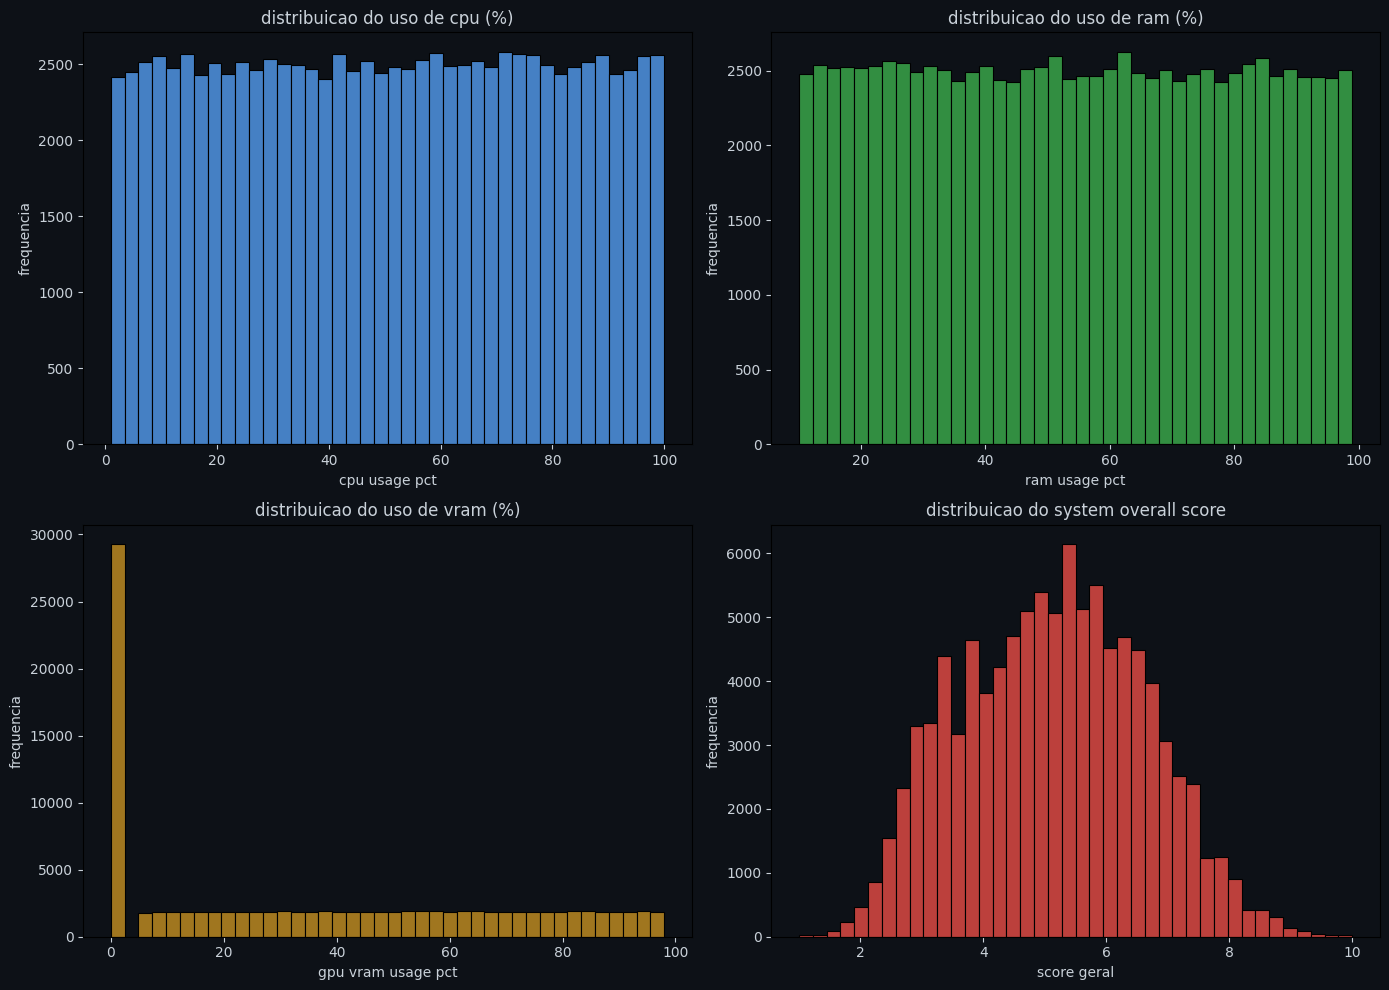

In [ ]:

#extracao de uma amostra representativa
df_sample = df_polars.select([
    'cpu_usage_pct', 'ram_usage_pct', 'gpu_vram_usage_pct', 'system_overall_score'
]).sample(n=100000, seed=42).to_pandas()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#1. histograma do uso de cpu
sns.histplot(df_sample['cpu_usage_pct'], bins=40, color='#58a6ff', ax=axes[0, 0])
axes[0, 0].set_title('distribuicao do uso de cpu (%)', fontsize=12)
axes[0, 0].set_xlabel('cpu usage pct')
axes[0, 0].set_ylabel('frequencia')

#2. histograma do uso de ram
sns.histplot(df_sample['ram_usage_pct'], bins=40, color='#3fb950', ax=axes[0, 1])
axes[0, 1].set_title('distribuicao do uso de ram (%)', fontsize=12)
axes[0, 1].set_xlabel('ram usage pct')
axes[0, 1].set_ylabel('frequencia')

#3. histograma do uso de vram
sns.histplot(df_sample['gpu_vram_usage_pct'], bins=40, color='#d29922', ax=axes[1, 0])
axes[1, 0].set_title('distribuicao do uso de vram (%)', fontsize=12)
axes[1, 0].set_xlabel('gpu vram usage pct')
axes[1, 0].set_ylabel('frequencia')

#4. histograma do score geral do sistema
sns.histplot(df_sample['system_overall_score'], bins=40, color='#f85149', ax=axes[1, 1])
axes[1, 1].set_title('distribuicao do system overall score', fontsize=12)
axes[1, 1].set_xlabel('score geral')
axes[1, 1].set_ylabel('frequencia')

plt.tight_layout()
plt.show()

> Os gráficos acima demonstram a frequência que cada elemento aparece na base de dado.

> O uso de CPU e RAM apresentam um gráfico homogêneo e bem distríbuido

> Com base no gráfico sobre o uso de vram podemos observar que em sua maioria o uso é próximo do 0%

> No gráfico de overall observamos que em sua maioria os computadores tem um desempenho médio


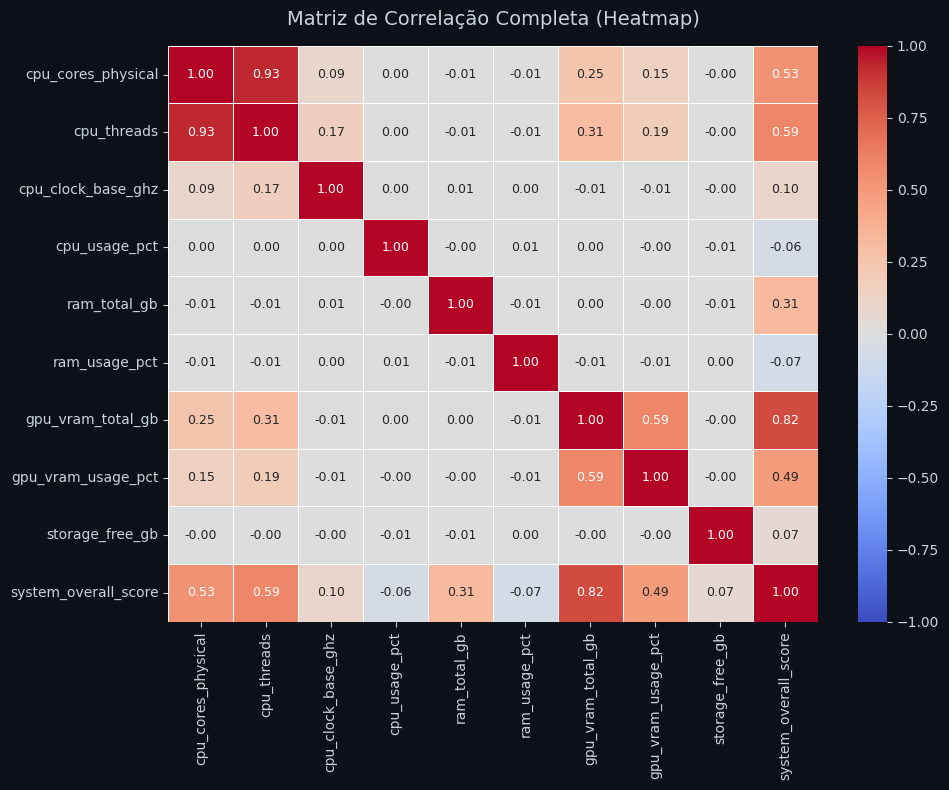

In [ ]:

#extracao de todas as variaveis numericas disponiveis na base para a amostra
colunas_numericas = [
    'cpu_cores_physical', 'cpu_threads', 'cpu_clock_base_ghz', 'cpu_usage_pct',
    'ram_total_gb', 'ram_usage_pct', 'gpu_vram_total_gb', 'gpu_vram_usage_pct',
    'storage_free_gb', 'system_overall_score'
]

df_corr = df_polars.select(colunas_numericas).sample(n=50000, seed=42).to_pandas()
matriz_corr = df_corr.corr()

#configuracao visual do grafico individual
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    ax=ax,
    cbar=True,
    linewidths=0.5,
    annot_kws={"size": 9}
)
ax.set_title('Matriz de Correlação Completa (Heatmap)', fontsize=14, pad=15)

plt.tight_layout()
plt.show()

>O heatmap acima demonstra a relação entre melhores componentes e melhor desempenho

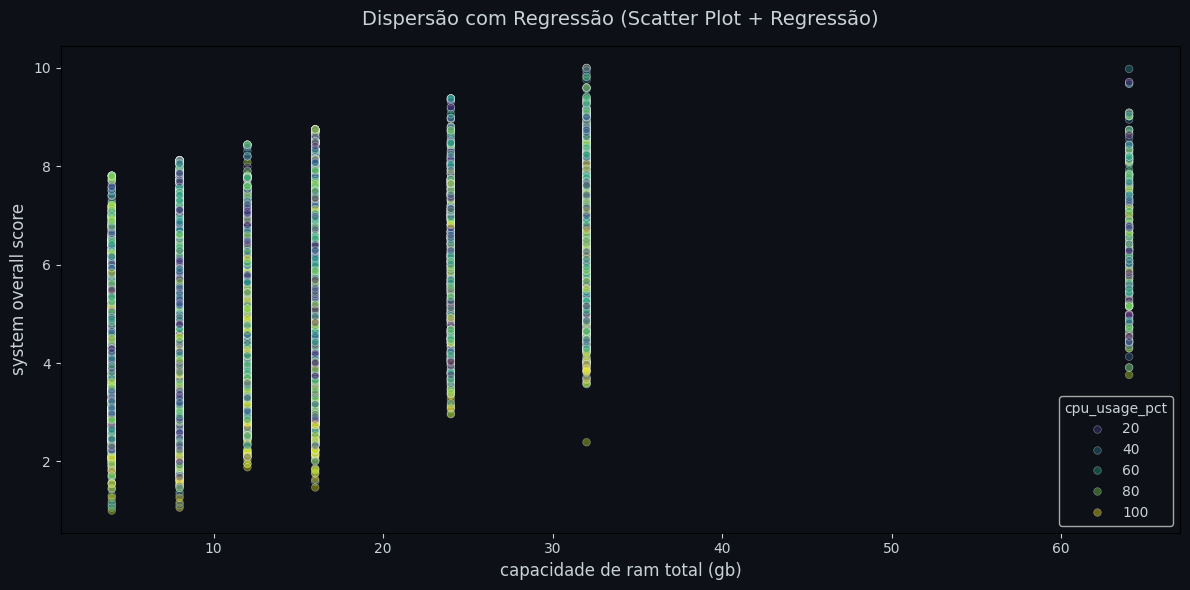

In [ ]:
#grafico de dispersao: ram total vs score geral do sistema
fig, ax = plt.subplots(figsize=(12, 6))

df_scatter = df_polars.select(['ram_total_gb', 'system_overall_score', 'cpu_usage_pct']).sample(n=30000, seed=42).to_pandas()

sns.scatterplot(
    data=df_scatter,
    x='ram_total_gb',
    y='system_overall_score',
    hue='cpu_usage_pct',
    palette='viridis',
    alpha=0.4,
    s=30,
    ax=ax
)

ax.set_title('Dispersão com Regressão (Scatter Plot + Regressão)', fontsize=14, pad=15)
ax.set_xlabel('capacidade de ram total (gb)', fontsize=12)
ax.set_ylabel('system overall score', fontsize=12)

plt.tight_layout()
plt.show()

> Nesse gráfico podemos observar que a quantidade de memória RAM pode aumentar o potencial máximo do sistema.

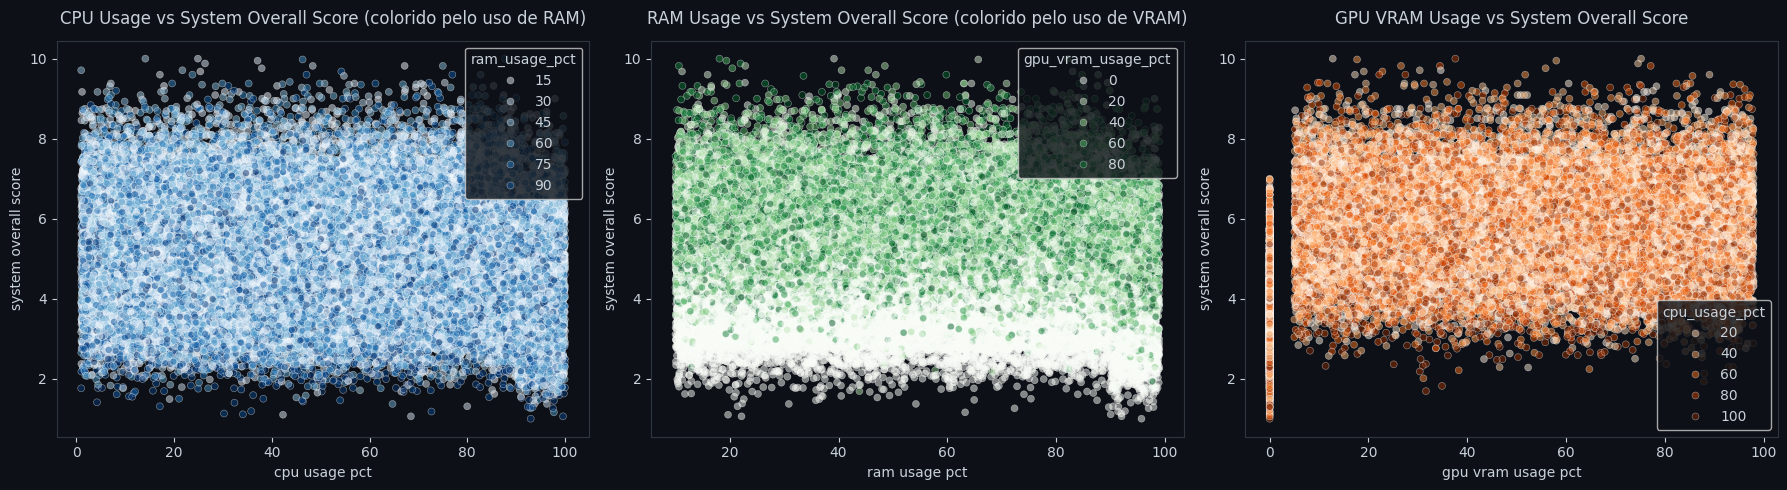

In [ ]:

# extracao de uma amostra representativa
df_scatter_sample = df_polars.select([
    'cpu_usage_pct', 'ram_usage_pct', 'gpu_vram_usage_pct', 'system_overall_score'
]).sample(n=40000, seed=42).to_pandas()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor='#0d1117')

# 1. dispersao: cpu usage vs system overall score (colorido por ram usage)
axes[0].set_facecolor('#0d1117')
sns.scatterplot(
    data=df_scatter_sample,
    x='cpu_usage_pct',
    y='system_overall_score',
    hue='ram_usage_pct',
    palette='Blues',
    alpha=0.5,
    s=25,
    ax=axes[0]
)
axes[0].set_title('CPU Usage vs System Overall Score (colorido pelo uso de RAM)', fontsize=12, pad=12, color='#c9d1d9')
axes[0].set_xlabel('cpu usage pct', fontsize=10, color='#c9d1d9')
axes[0].set_ylabel('system overall score', fontsize=10, color='#c9d1d9')

# 2. dispersao: ram usage vs system overall score (colorido por vram usage)
axes[1].set_facecolor('#0d1117')
sns.scatterplot(
    data=df_scatter_sample,
    x='ram_usage_pct',
    y='system_overall_score',
    hue='gpu_vram_usage_pct',
    palette='Greens',
    alpha=0.5,
    s=25,
    ax=axes[1]
)
axes[1].set_title('RAM Usage vs System Overall Score (colorido pelo uso de VRAM)', fontsize=12, pad=12, color='#c9d1d9')
axes[1].set_xlabel('ram usage pct', fontsize=10, color='#c9d1d9')
axes[1].set_ylabel('system overall score', fontsize=10, color='#c9d1d9')

# 3. dispersao: vram usage vs system overall score (colorido por cpu usage)
axes[2].set_facecolor('#0d1117')
sns.scatterplot(
    data=df_scatter_sample,
    x='gpu_vram_usage_pct',
    y='system_overall_score',
    hue='cpu_usage_pct',
    palette='Oranges',
    alpha=0.5,
    s=25,
    ax=axes[2]
)
axes[2].set_title('GPU VRAM Usage vs System Overall Score', fontsize=12, pad=12, color='#c9d1d9')
axes[2].set_xlabel('gpu vram usage pct', fontsize=10, color='#c9d1d9')
axes[2].set_ylabel('system overall score', fontsize=10, color='#c9d1d9')

# configuracao visual de cores para eixos
for ax in axes:
    ax.tick_params(colors='#c9d1d9', axis='x')
    ax.tick_params(colors='#c9d1d9', axis='y')
    if ax.legend_:
        for text in ax.legend_.get_texts():
            text.set_color('#c9d1d9')
        if ax.legend_.get_title():
            ax.legend_.get_title().set_color('#c9d1d9')
    for spine in ax.spines.values():
        spine.set_color('#30363d')

plt.tight_layout()
plt.show()

> Os gráficos indicam que isoladamente esses componentes não tem interferem tanto no Overall Score

/tmp/ipykernel_652/3549941092.py:7: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_652/3549941092.py:21: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_652/3549941092.py:35: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_652/3549941092.py:49: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




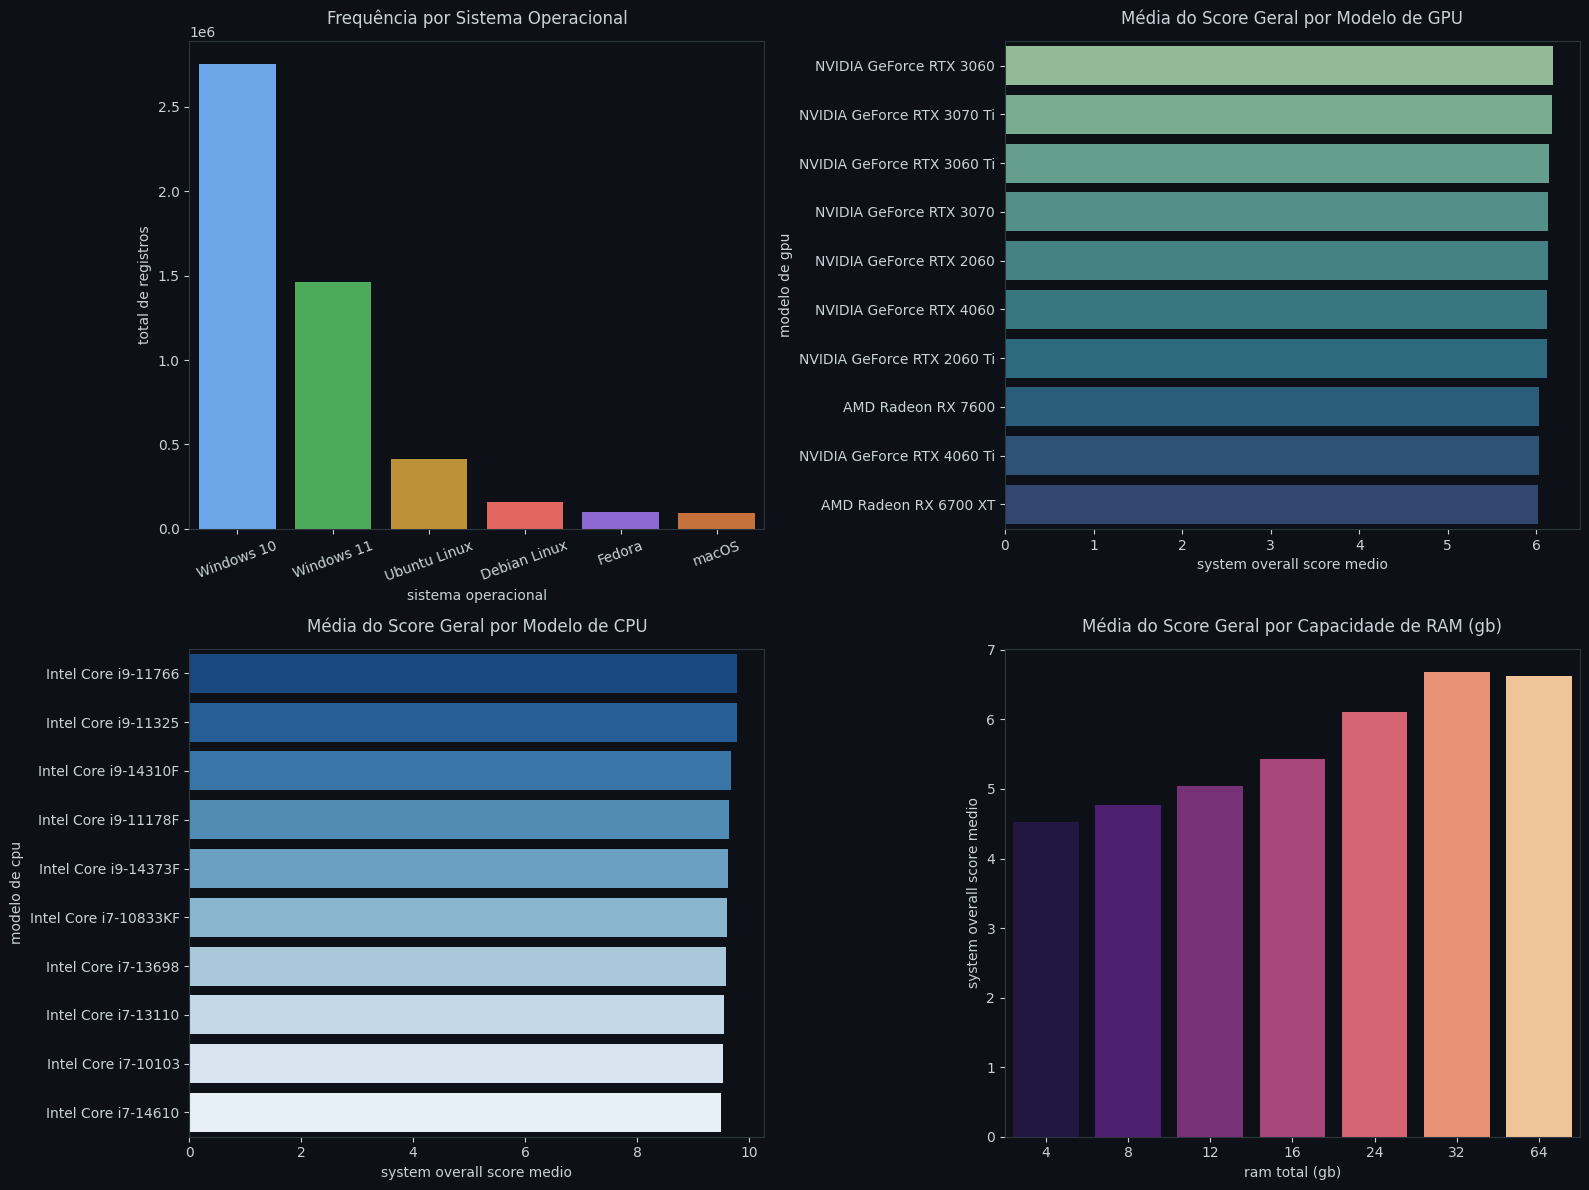

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(16, 12), facecolor='#0d1117')

# 1. frequencia por sistema operacional
df_os = df_polars.select(['os_name']).to_pandas()
os_counts = df_os['os_name'].value_counts()
axes[0, 0].set_facecolor('#0d1117')
sns.barplot(
    x=os_counts.index, y=os_counts.values, ax=axes[0, 0],
    palette=['#58a6ff', '#3fb950', '#d29922', '#f85149', '#8957e5', '#db6d28']
)
axes[0, 0].set_title('Frequência por Sistema Operacional', fontsize=12, pad=12, color='#c9d1d9')
axes[0, 0].set_xlabel('sistema operacional', fontsize=10, color='#c9d1d9')
axes[0, 0].set_ylabel('total de registros', fontsize=10, color='#c9d1d9')
axes[0, 0].tick_params(colors='#c9d1d9', axis='x', rotation=20)
axes[0, 0].tick_params(colors='#c9d1d9', axis='y')

# 2. media do score geral por modelo de gpu
df_gpu_score = df_polars.select(['gpu_model', 'system_overall_score']).to_pandas()
gpu_avg = df_gpu_score.groupby('gpu_model')['system_overall_score'].mean().sort_values(ascending=False).head(10)
axes[0, 1].set_facecolor('#0d1117')
sns.barplot(
    x=gpu_avg.values, y=gpu_avg.index, ax=axes[0, 1],
    palette='crest'
)
axes[0, 1].set_title('Média do Score Geral por Modelo de GPU', fontsize=12, pad=12, color='#c9d1d9')
axes[0, 1].set_xlabel('system overall score medio', fontsize=10, color='#c9d1d9')
axes[0, 1].set_ylabel('modelo de gpu', fontsize=10, color='#c9d1d9')
axes[0, 1].tick_params(colors='#c9d1d9', axis='x')
axes[0, 1].tick_params(colors='#c9d1d9', axis='y')

# 3. media do score geral por modelo de cpu
df_cpu_score = df_polars.select(['cpu_model', 'system_overall_score']).to_pandas()
cpu_avg = df_cpu_score.groupby('cpu_model')['system_overall_score'].mean().sort_values(ascending=False).head(10)
axes[1, 0].set_facecolor('#0d1117')
sns.barplot(
    x=cpu_avg.values, y=cpu_avg.index, ax=axes[1, 0],
    palette='Blues_r'
)
axes[1, 0].set_title('Média do Score Geral por Modelo de CPU', fontsize=12, pad=12, color='#c9d1d9')
axes[1, 0].set_xlabel('system overall score medio', fontsize=10, color='#c9d1d9')
axes[1, 0].set_ylabel('modelo de cpu', fontsize=10, color='#c9d1d9')
axes[1, 0].tick_params(colors='#c9d1d9', axis='x')
axes[1, 0].tick_params(colors='#c9d1d9', axis='y')

# 4. media do score geral por capacidade de ram
df_vram_score = df_polars.select(['ram_total_gb', 'system_overall_score']).to_pandas()
vram_avg = df_vram_score.groupby('ram_total_gb')['system_overall_score'].mean().sort_index()
axes[1, 1].set_facecolor('#0d1117')
sns.barplot(
    x=vram_avg.index, y=vram_avg.values, ax=axes[1, 1],
    palette='magma'
)
axes[1, 1].set_title('Média do Score Geral por Capacidade de RAM (gb)', fontsize=12, pad=12, color='#c9d1d9')
axes[1, 1].set_xlabel('ram total (gb)', fontsize=10, color='#c9d1d9')
axes[1, 1].set_ylabel('system overall score medio', fontsize=10, color='#c9d1d9')
axes[1, 1].tick_params(colors='#c9d1d9', axis='x')
axes[1, 1].tick_params(colors='#c9d1d9', axis='y')

# configuracao de cores das bordas
for row in axes:
    for ax in row:
        for spine in ax.spines.values():
            spine.set_color('#30363d')

plt.tight_layout()
plt.show()

> O gráfico de frequência de Sistema Operacional demonstra uma dominância no uso de Windows em relação aos demais.

> No gráfico sobre score por GPU podemos observar que GPUss da NVIDIA demonstram um maior desempenho.

> No gráfico de score por CPU novamente tem uma dominância em maior desempenho com CPUs Intel.

> O último gráfico demonstra que quanto maior a capacidade de RAM maior é seu score.




/tmp/ipykernel_652/3772543565.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




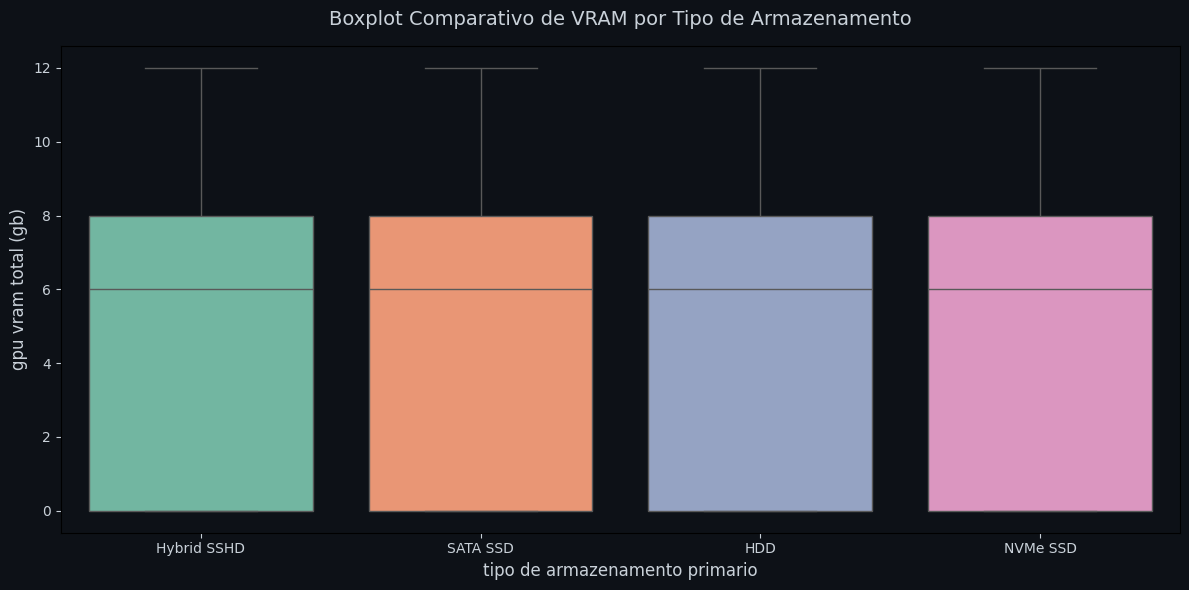

In [ ]:
#boxplot comparativo: vram dedicada vs tipo de armazenamento
fig, ax = plt.subplots(figsize=(12, 6))

df_box = df_polars.select(['storage_primary_type', 'gpu_vram_total_gb']).sample(n=40000, seed=42).to_pandas()

sns.boxplot(
    data=df_box,
    x='storage_primary_type',
    y='gpu_vram_total_gb',
    palette='Set2',
    ax=ax
)

ax.set_title('Boxplot Comparativo de VRAM por Tipo de Armazenamento', fontsize=14, pad=15)
ax.set_xlabel('tipo de armazenamento primario', fontsize=12)
ax.set_ylabel('gpu vram total (gb)', fontsize=12)

plt.tight_layout()
plt.show()

> Neste gráfico observamos que o tipo de armazenamento usado é bem variado independente da quantidade de VRAM.

/tmp/ipykernel_652/856587601.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_652/856587601.py:46: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




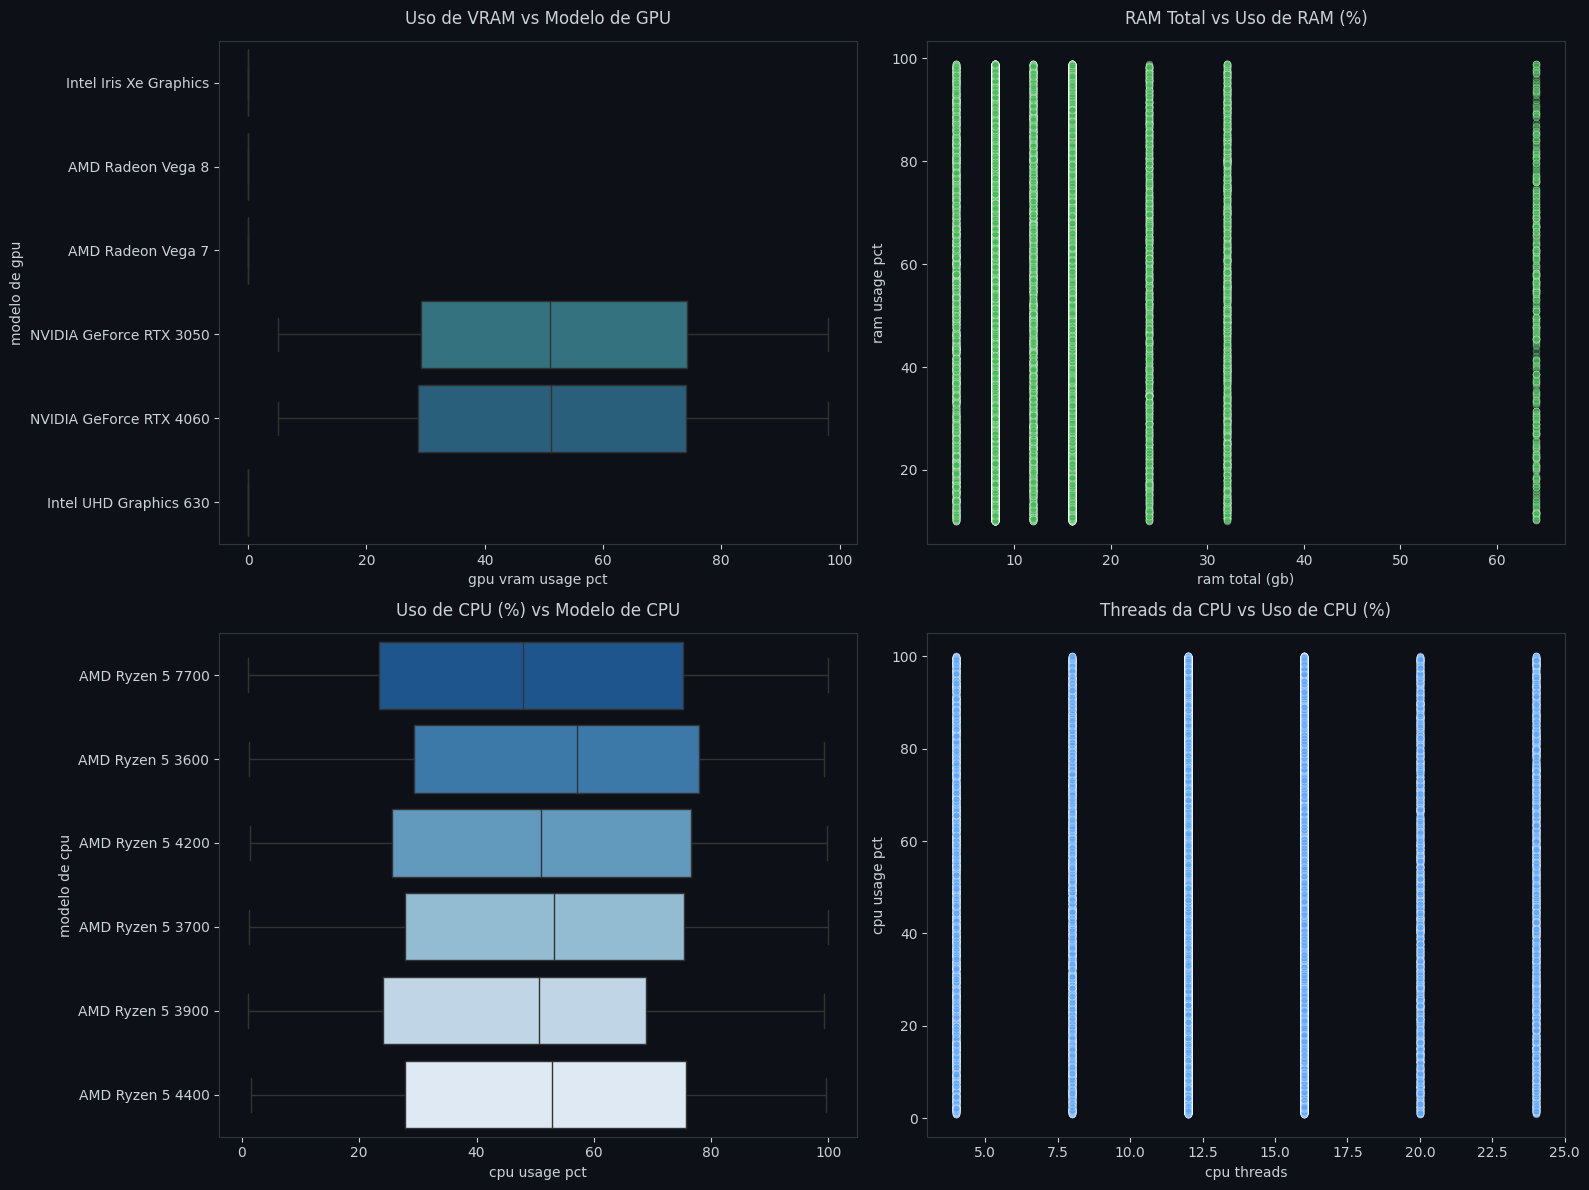

In [ ]:

# extracao de uma amostra representativa
df_mult_sample = df_polars.select([
    'gpu_model', 'gpu_vram_usage_pct',
    'ram_total_gb', 'ram_usage_pct',
    'cpu_model', 'cpu_usage_pct',
    'cpu_threads'
]).sample(n=40000, seed=42).to_pandas()

fig, axes = plt.subplots(2, 2, figsize=(16, 12), facecolor='#0d1117')

# 1. uso de vram por modelo de gpu (top 6 modelos)
top_gpus = df_mult_sample['gpu_model'].value_counts().head(6).index
df_gpu_sub = df_mult_sample[df_mult_sample['gpu_model'].isin(top_gpus)]
axes[0, 0].set_facecolor('#0d1117')
sns.boxplot(
    data=df_gpu_sub,
    x='gpu_vram_usage_pct',
    y='gpu_model',
    ax=axes[0, 0],
    palette='crest',
    linewidth=1
)
axes[0, 0].set_title('Uso de VRAM vs Modelo de GPU', fontsize=12, pad=12, color='#c9d1d9')
axes[0, 0].set_xlabel('gpu vram usage pct', fontsize=10, color='#c9d1d9')
axes[0, 0].set_ylabel('modelo de gpu', fontsize=10, color='#c9d1d9')

# 2. ram total (gb) vs uso de ram (%)
axes[0, 1].set_facecolor('#0d1117')
sns.scatterplot(
    data=df_mult_sample,
    x='ram_total_gb',
    y='ram_usage_pct',
    alpha=0.4,
    color='#3fb950',
    s=25,
    ax=axes[0, 1]
)
axes[0, 1].set_title('RAM Total vs Uso de RAM (%)', fontsize=12, pad=12, color='#c9d1d9')
axes[0, 1].set_xlabel('ram total (gb)', fontsize=10, color='#c9d1d9')
axes[0, 1].set_ylabel('ram usage pct', fontsize=10, color='#c9d1d9')

# 3. uso de cpu por modelo de cpu (top 6 modelos)
top_cpus = df_mult_sample['cpu_model'].value_counts().head(6).index
df_cpu_sub = df_mult_sample[df_mult_sample['cpu_model'].isin(top_cpus)]
axes[1, 0].set_facecolor('#0d1117')
sns.boxplot(
    data=df_cpu_sub,
    x='cpu_usage_pct',
    y='cpu_model',
    ax=axes[1, 0],
    palette='Blues_r',
    linewidth=1
)
axes[1, 0].set_title('Uso de CPU (%) vs Modelo de CPU', fontsize=12, pad=12, color='#c9d1d9')
axes[1, 0].set_xlabel('cpu usage pct', fontsize=10, color='#c9d1d9')
axes[1, 0].set_ylabel('modelo de cpu', fontsize=10, color='#c9d1d9')

# 4. cpu threads vs uso de cpu (%)
axes[1, 1].set_facecolor('#0d1117')
sns.scatterplot(
    data=df_mult_sample,
    x='cpu_threads',
    y='cpu_usage_pct',
    alpha=0.4,
    color='#58a6ff',
    s=25,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Threads da CPU vs Uso de CPU (%)', fontsize=12, pad=12, color='#c9d1d9')
axes[1, 1].set_xlabel('cpu threads', fontsize=10, color='#c9d1d9')
axes[1, 1].set_ylabel('cpu usage pct', fontsize=10, color='#c9d1d9')

# configuracao visual unificada de cores
for row in axes:
    for ax in row:
        ax.tick_params(colors='#c9d1d9', axis='x')
        ax.tick_params(colors='#c9d1d9', axis='y')
        for spine in ax.spines.values():
            spine.set_color('#30363d')

plt.tight_layout()
plt.show()

> No primeiro gráfico é possível observar que GPUs integradas não utilizam VRAM própria.
> Nos demais gráficos vemos que os componentes foram testados ao limite, apresentando porcentagens distribuídas de uso.

# **Arquitetura Analítica (Data Warehouse)**

## **Justificativa: Data Warehouse em vez de Data Lake**

Os dados são estruturados e tabulares (19 variáveis de esquema fixo, tratadas em R) e o objetivo é responder a perguntas agregadas por meio de OLAP. Para isso, o esquema estrela, com limpeza antes da carga (*schema-on-write*), garante consistência e bom desempenho. Um Data Lake só faria sentido com dados brutos não estruturados ou semiestruturados, como JSON e logs.

## **Fluxo ETL (Extração, Transformação e Carga)**

Os dados são extraídos, **transformados e validados antes** da carga no Data Warehouse.

```
Gerador (Python) ──► CSV bruto ──► Tratamento (R) ──► CSV tratado ──► Leitura (Polars) ──► Carga em lotes ──► Data Warehouse (SQLite) ──► OLAP / ML / Spark
```


**1. Extração**
- O script `gerador_hardware.py` gera o arquivo `gerador_hardware.csv` na VM geradora, de forma incremental (até 5.000.000 de eventos).
- O CSV é disponibilizado à VM consumidora, provisionada com OpenTofu e Ansible.

**2. Transformação**
- **Limpeza em R** (`tratar_telemetria.R`): padronização de categorias, tratamento de nulos, remoção de outliers e de duplicidades. Resultado: `dados_hardware_tratados.csv`, com **4.975.224 registros** e 19 variáveis.
- **Modelagem dimensional no Colab:** leitura com Polars, separação em dimensões e fato, criação de chaves substitutas (`sk_*`) e da chave temporal `sk_tempo` (formato `AAAAMMDDHH`).

**3. Carga**
- Destino: Data Warehouse em SQLite (`dw_hardware_analitico.db`).
- Primeiro as dimensões, depois a tabela fato, em **lotes de 500.000 linhas**, para evitar estouro de memória.

**Modelo dimensional resultante**

| Tabela | Tipo | Conteúdo |
| :--- | :--- | :--- |
| `fato_telemetria` | Fato | `event_id`, chaves das dimensões e métricas de uso, RAM, armazenamento e score |
| `dim_maquina` | Dimensão | `system_id` |
| `dim_cpu` | Dimensão | modelo, núcleos físicos, threads e clock base |
| `dim_gpu` | Dimensão | modelo e VRAM total |
| `dim_sistema` | Dimensão | SO, versão, tipo de armazenamento e resolução |
| `dim_tempo` | Dimensão | data/hora, ano, mês, dia, hora e dia da semana |



In [ ]:
#df_polars
caminho_dw = os.path.join(PASTA, 'dw_hardware_analitico.db')

#recria o banco do zero para nao duplicar a tabela fato ao reexecutar
if os.path.exists(caminho_dw):
    print("removendo banco antigo para reconstruir do zero...")
    os.remove(caminho_dw)

conn = sqlite3.connect(caminho_dw)
cursor = conn.cursor()
cursor.execute('PRAGMA journal_mode = OFF')   #carga mais rapida
cursor.execute('PRAGMA synchronous = OFF')

#criacao das tabelas do esquema estrela
print("1. criando as tabelas do esquema estrela...")
cursor.execute('CREATE TABLE dim_maquina (sk_maquina INTEGER PRIMARY KEY AUTOINCREMENT, system_id TEXT UNIQUE)')
cursor.execute('CREATE TABLE dim_cpu (sk_cpu INTEGER PRIMARY KEY AUTOINCREMENT, cpu_model TEXT, cpu_cores_physical INTEGER, cpu_threads INTEGER, cpu_clock_base_ghz REAL)')
cursor.execute('CREATE TABLE dim_gpu (sk_gpu INTEGER PRIMARY KEY AUTOINCREMENT, gpu_model TEXT, gpu_vram_total_gb REAL)')
cursor.execute('CREATE TABLE dim_sistema (sk_sistema INTEGER PRIMARY KEY AUTOINCREMENT, os_name TEXT, os_version TEXT, storage_primary_type TEXT, display_resolution TEXT)')
cursor.execute('CREATE TABLE dim_tempo (sk_tempo INTEGER PRIMARY KEY, timestamp_original TEXT, ano INTEGER, mes INTEGER, dia INTEGER, hora INTEGER, dia_da_semana INTEGER)')
cursor.execute('''
CREATE TABLE fato_telemetria (
    sk_telemetria INTEGER PRIMARY KEY AUTOINCREMENT,
    event_id TEXT,
    sk_maquina INTEGER,
    sk_cpu INTEGER,
    sk_gpu INTEGER,
    sk_sistema INTEGER,
    sk_tempo INTEGER,
    cpu_usage_pct REAL,
    ram_total_gb REAL,
    ram_usage_pct REAL,
    gpu_vram_usage_pct REAL,
    storage_free_gb REAL,
    system_overall_score REAL
)
''')
conn.commit()

#populacao das dimensoes
print("2. populando dimensoes...")
df_polars.select(['system_id']).unique().to_pandas().to_sql('dim_maquina', conn, if_exists='append', index=False)
df_polars.select(['cpu_model', 'cpu_cores_physical', 'cpu_threads', 'cpu_clock_base_ghz']).unique().to_pandas().to_sql('dim_cpu', conn, if_exists='append', index=False)
df_polars.select(['gpu_model', 'gpu_vram_total_gb']).unique().to_pandas().to_sql('dim_gpu', conn, if_exists='append', index=False)
df_polars.select(['os_name', 'os_version', 'storage_primary_type', 'display_resolution']).unique().to_pandas().to_sql('dim_sistema', conn, if_exists='append', index=False)

#funcao unica para a chave temporal (AAAAMMDDHH), usada na dimensao e na fato
def chave_tempo(dt):
    return dt.dt.year * 1000000 + dt.dt.month * 10000 + dt.dt.day * 100 + dt.dt.hour

#dimensao temporal
timestamps_s = df_polars['timestamp'].to_pandas()
dt_series = pd.to_datetime(timestamps_s, errors='coerce')
df_tempo = pd.DataFrame({
    'sk_tempo': chave_tempo(dt_series),
    'timestamp_original': timestamps_s.astype(str),
    'ano': dt_series.dt.year,
    'mes': dt_series.dt.month,
    'dia': dt_series.dt.day,
    'hora': dt_series.dt.hour,
    'dia_da_semana': dt_series.dt.dayofweek
}).dropna(subset=['sk_tempo']).drop_duplicates(subset=['sk_tempo'])
df_tempo.to_sql('dim_tempo', conn, if_exists='append', index=False)
del timestamps_s, dt_series, df_tempo
conn.commit()
print("dimensoes concluidas!")

#mapas de chaves carregados uma unica vez (antes eram relidos a cada lote)
print("3. carregando mapas de chaves...")
map_maquina = dict(pd.read_sql("SELECT system_id, sk_maquina FROM dim_maquina", conn).values)
dim_cpu = pd.read_sql("SELECT sk_cpu, cpu_model, cpu_cores_physical, cpu_threads, cpu_clock_base_ghz FROM dim_cpu", conn)
dim_gpu = pd.read_sql("SELECT sk_gpu, gpu_model, gpu_vram_total_gb FROM dim_gpu", conn)
dim_sistema = pd.read_sql("SELECT sk_sistema, os_name, os_version, storage_primary_type, display_resolution FROM dim_sistema", conn)

colunas_fato = [
    'event_id', 'sk_maquina', 'sk_cpu', 'sk_gpu', 'sk_sistema', 'sk_tempo',
    'cpu_usage_pct', 'ram_total_gb', 'ram_usage_pct', 'gpu_vram_usage_pct',
    'storage_free_gb', 'system_overall_score'
]

print("4. inserindo dados na tabela fato em lotes...")
tamanho_lote = 500000
total_linhas = len(df_polars)

for inicio in range(0, total_linhas, tamanho_lote):
    fim = min(inicio + tamanho_lote, total_linhas)
    print(f"processando lote: {inicio} ate {fim}...")

    df_lote = df_polars.slice(inicio, fim - inicio).to_pandas()
    df_lote['sk_tempo'] = chave_tempo(pd.to_datetime(df_lote['timestamp'], errors='coerce'))
    df_lote['sk_maquina'] = df_lote['system_id'].map(map_maquina)

    df_lote = df_lote.merge(dim_cpu, on=['cpu_model', 'cpu_cores_physical', 'cpu_threads', 'cpu_clock_base_ghz'], how='left') \
                     .merge(dim_gpu, on=['gpu_model', 'gpu_vram_total_gb'], how='left') \
                     .merge(dim_sistema, on=['os_name', 'os_version', 'storage_primary_type', 'display_resolution'], how='left')

    df_lote[colunas_fato].to_sql('fato_telemetria', conn, if_exists='append', index=False, chunksize=100000)
    conn.commit()

#a fato deve ter o mesmo total de linhas e nenhuma chave nula
n_fato = cursor.execute('SELECT COUNT(*) FROM fato_telemetria').fetchone()[0]
nulos = cursor.execute('''
    SELECT SUM(sk_maquina IS NULL), SUM(sk_cpu IS NULL), SUM(sk_gpu IS NULL),
           SUM(sk_sistema IS NULL), SUM(sk_tempo IS NULL)
    FROM fato_telemetria
''').fetchone()
print(f"\nlinhas na fato: {n_fato} (esperado: {total_linhas})")
print(f"chaves nulas (maquina, cpu, gpu, sistema, tempo): {nulos}")

conn.close()
print("data warehouse criado e populado com sucesso!")

1. criando as tabelas do esquema estrela...
2. populando dimensoes...
dimensoes concluidas!
3. carregando mapas de chaves...
4. inserindo dados na tabela fato em lotes...
processando lote: 0 ate 500000...
processando lote: 500000 ate 1000000...
processando lote: 1000000 ate 1500000...
processando lote: 1500000 ate 2000000...
processando lote: 2000000 ate 2500000...
processando lote: 2500000 ate 3000000...
processando lote: 3000000 ate 3500000...
processando lote: 3500000 ate 4000000...
processando lote: 4000000 ate 4500000...
processando lote: 4500000 ate 4975224...

linhas na fato: 4975224 (esperado: 4975224)
chaves nulas (maquina, cpu, gpu, sistema, tempo): (0, 0, 0, 0, 0)
data warehouse criado e populado com sucesso!


# **Arquitetura Analítica (OLAP)**

## **Conexão das operações OLAP e de Data Mining com a situação-problema**

| Operação | Pergunta que responde | Game development | Infraestrutura corporativa (TI) |
| :--- | :--- | :--- | :--- |
| Roll-up temporal (mês) | A demanda de recursos muda ao longo do tempo? | Ver se o perfil dos jogadores é estável | Planejar capacidade sem sazonalidade escondida |
| Drill-down (mês → dia; SO → versão) | Onde, dentro da média, está a variação? | Priorizar SO e versão com mais jogadores | Localizar versões de SO com mais carga |
| Slice & Dice (disco × núcleos, RAM > 50%) | Qual combinação de hardware entrega melhor score? | Definir requisitos mínimos e recomendados | Decidir entre trocar HDD por SSD ou aumentar núcleos |
| Gargalos por capacidade (RAM e VRAM) | Máquinas com mais memória sofrem menos pressão? | Estimar quanta RAM e VRAM o jogo realmente exige | Decidir se vale ampliar memória |
| Classificação de perfil (Random Forest) | O hardware sozinho indica o perfil da máquina? | Segmentar a base de jogadores | Classificar o parque em faixas de renovação |
| K-Means (perfis de uso) | Há grupos de máquinas com comportamento de uso parecido? | Identificar grupos com folga ou no limite | Separar máquinas subdimensionadas e superdimensionadas |

--- olap drill-down: mes -> dia ---
    ano  mes  dia  volume  media_cpu  media_ram  media_score        data
0  2026    9   19   43324      50.55      54.43         5.13  2026-09-19
1  2026    9   20  166127      50.40      54.48         5.12  2026-09-20
2  2026    9   21  165425      50.39      54.53         5.12  2026-09-21
3  2026    9   22  166177      50.54      54.50         5.12  2026-09-22
4  2026    9   23  166008      50.55      54.44         5.12  2026-09-23
5  2026    9   24  166090      50.64      54.49         5.12  2026-09-24
6  2026    9   25  165423      50.35      54.60         5.12  2026-09-25
7  2026    9   26  166164      50.62      54.46         5.12  2026-09-26
8  2026    9   27  165812      50.48      54.49         5.12  2026-09-27
9  2026    9   28  165656      50.58      54.58         5.12  2026-09-28


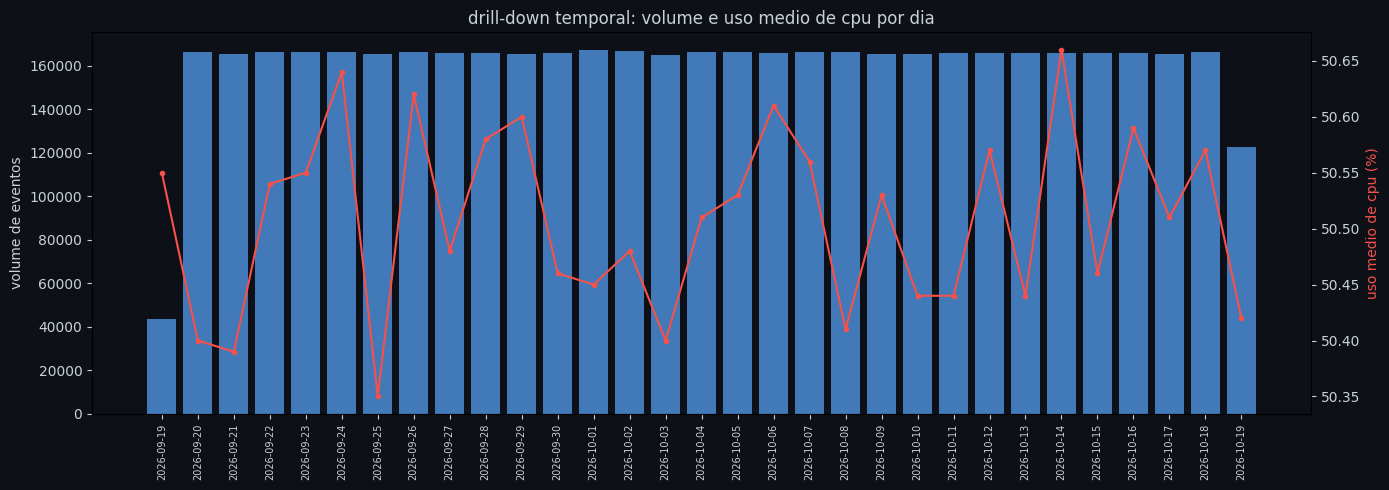


--- olap drill-down: sistema operacional -> versao ---
        os_name os_version   volume  media_cpu  media_ram  media_score
0  Debian Linux  22.04 LTS   158058      50.49      54.45         5.05
1        Fedora       14.2    97733      50.50      54.42         5.09
2  Ubuntu Linux  22.04 LTS   412292      50.55      54.57         5.15
3    Windows 10       22H2  2751311      50.50      54.50         5.13
4    Windows 11       22H2  1460713      50.52      54.50         5.12
5         macOS       14.2    95117      50.49      54.54         5.03


In [ ]:
caminho_dw = os.path.join(PASTA, 'dw_hardware_analitico.db')
conn = sqlite3.connect(caminho_dw)

#drill-down temporal: do mes (roll-up) para o dia
df_dia = pd.read_sql('''
    SELECT t.ano, t.mes, t.dia,
           COUNT(f.sk_telemetria) AS volume,
           ROUND(AVG(f.cpu_usage_pct), 2) AS media_cpu,
           ROUND(AVG(f.ram_usage_pct), 2) AS media_ram,
           ROUND(AVG(f.system_overall_score), 2) AS media_score
    FROM fato_telemetria f
    JOIN dim_tempo t ON f.sk_tempo = t.sk_tempo
    GROUP BY t.ano, t.mes, t.dia
    ORDER BY t.ano, t.mes, t.dia
''', conn)
df_dia['data'] = (df_dia['ano'].astype(str) + '-' + df_dia['mes'].astype(str).str.zfill(2)
                  + '-' + df_dia['dia'].astype(str).str.zfill(2))
print("--- olap drill-down: mes -> dia ---")
print(df_dia.head(10))

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(df_dia['data'], df_dia['volume'], color='#58a6ff', alpha=0.7)
ax1.set_ylabel('volume de eventos')
ax1.tick_params(axis='x', rotation=90, labelsize=7)
ax2 = ax1.twinx()
ax2.plot(df_dia['data'], df_dia['media_cpu'], color='#f85149', marker='o', markersize=3)
ax2.set_ylabel('uso medio de cpu (%)', color='#f85149')
ax1.set_title('drill-down temporal: volume e uso medio de cpu por dia')
plt.tight_layout()
plt.show()

#drill-down por hardware: do sistema operacional para a versao
df_os = pd.read_sql('''
    SELECT s.os_name, s.os_version,
           COUNT(f.sk_telemetria) AS volume,
           ROUND(AVG(f.cpu_usage_pct), 2) AS media_cpu,
           ROUND(AVG(f.ram_usage_pct), 2) AS media_ram,
           ROUND(AVG(f.system_overall_score), 2) AS media_score
    FROM fato_telemetria f
    JOIN dim_sistema s ON f.sk_sistema = s.sk_sistema
    GROUP BY s.os_name, s.os_version
    ORDER BY s.os_name, volume DESC
''', conn)
print("\n--- olap drill-down: sistema operacional -> versao ---")
print(df_os.head(20))
conn.close()

   ram_total_gb    total  pct_ram_critica  media_score
0           4.0   394795            15.76         4.53
1           8.0  2234470            15.71         4.78
2          12.0   347340            15.70         5.04
3          16.0  1594766            15.75         5.43
4          24.0   147238            15.72         6.11
5          32.0   207133            15.71         6.68
6          64.0    49482            15.49         6.63

   gpu_vram_total_gb    total  pct_vram_critica  media_score
0                0.0  1462236              0.00         3.55
1                3.0    78017              8.56         3.84
2                4.0   659209              8.60         4.74
3                6.0   848896              8.62         5.39
4                8.0  1023269              8.60         5.84
5               12.0   903597              8.56         6.98


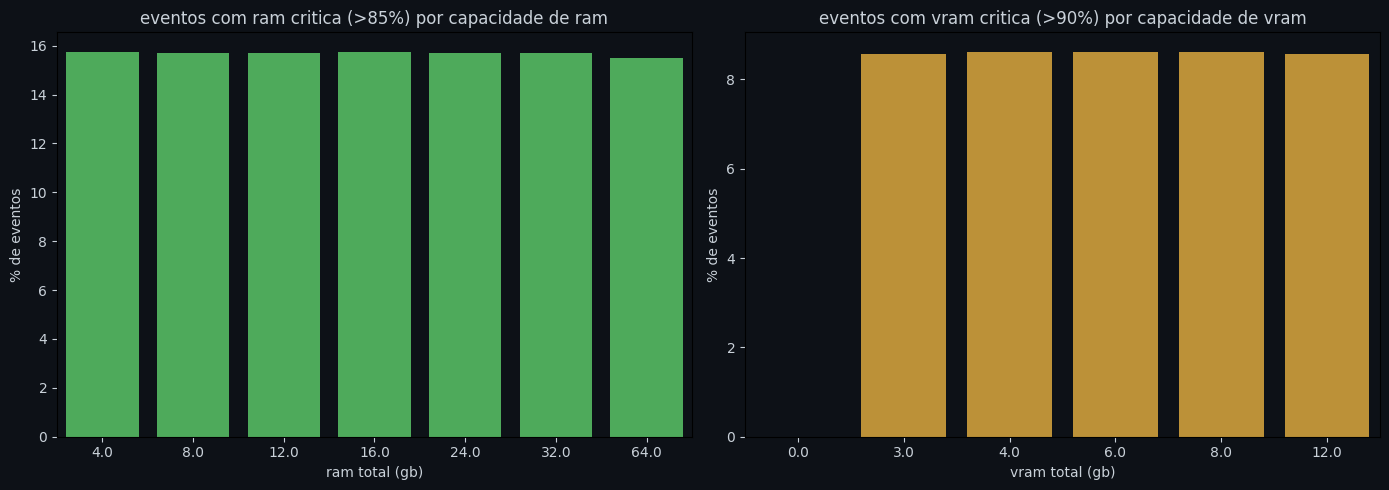

In [ ]:
conn = sqlite3.connect(os.path.join(PASTA, 'dw_hardware_analitico.db'))

#percentual de eventos com RAM critica (>85%) por capacidade de RAM
df_ram = pd.read_sql('''
    SELECT f.ram_total_gb,
           COUNT(*) AS total,
           ROUND(100.0 * SUM(f.ram_usage_pct > 85) / COUNT(*), 2) AS pct_ram_critica,
           ROUND(AVG(f.system_overall_score), 2) AS media_score
    FROM fato_telemetria f
    GROUP BY f.ram_total_gb
    ORDER BY f.ram_total_gb
''', conn)

#percentual de eventos com VRAM critica (>90%) por capacidade de VRAM
df_vram = pd.read_sql('''
    SELECT g.gpu_vram_total_gb,
           COUNT(*) AS total,
           ROUND(100.0 * SUM(f.gpu_vram_usage_pct > 90) / COUNT(*), 2) AS pct_vram_critica,
           ROUND(AVG(f.system_overall_score), 2) AS media_score
    FROM fato_telemetria f
    JOIN dim_gpu g ON f.sk_gpu = g.sk_gpu
    GROUP BY g.gpu_vram_total_gb
    ORDER BY g.gpu_vram_total_gb
''', conn)
conn.close()

print(df_ram); print(); print(df_vram)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df_ram, x='ram_total_gb', y='pct_ram_critica', color='#3fb950', ax=axes[0])
axes[0].set_title('eventos com ram critica (>85%) por capacidade de ram')
axes[0].set_xlabel('ram total (gb)'); axes[0].set_ylabel('% de eventos')
sns.barplot(data=df_vram, x='gpu_vram_total_gb', y='pct_vram_critica', color='#d29922', ax=axes[1])
axes[1].set_title('eventos com vram critica (>90%) por capacidade de vram')
axes[1].set_xlabel('vram total (gb)'); axes[1].set_ylabel('% de eventos')
plt.tight_layout()
plt.show()

--- olap roll-up ---
    ano  mes  volume_amostras  media_cpu_usage_pct  media_score_geral
0  2026    9          1867354                50.51               5.12
1  2026   10          3107870                50.50               5.12
--- olap slice & dice ---
   storage_primary_type  cpu_cores_physical  media_ram_usage_pct  \
0              NVMe SSD                  16                74.43   
1              NVMe SSD                  12                74.52   
2              SATA SSD                  12                74.52   
3              SATA SSD                  16                74.54   
4              NVMe SSD                  10                74.44   
5                   HDD                  12                74.59   
6              NVMe SSD                   8                74.52   
7                   HDD                  16                74.56   
8              SATA SSD                  10                74.54   
9              SATA SSD                   8                74.4

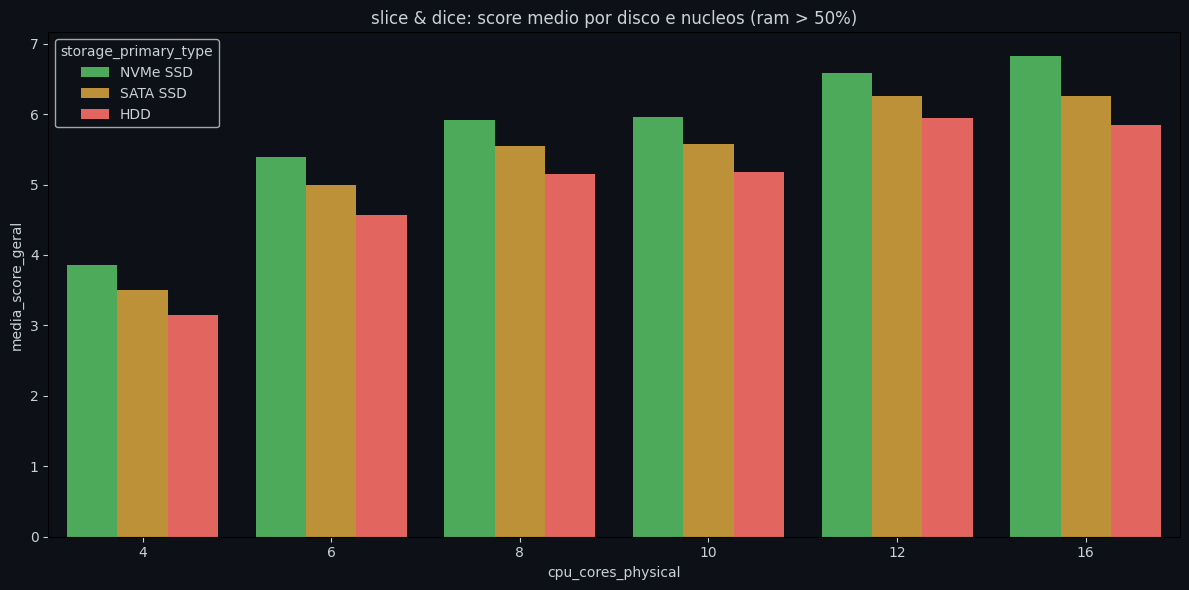

In [ ]:
conn = sqlite3.connect(os.path.join(PASTA, 'dw_hardware_analitico.db'))

#olap roll-up (agregacao temporal por ano e mes)
df_ru = pd.read_sql('''
    SELECT t.ano, t.mes, COUNT(f.sk_telemetria) AS volume_amostras,
           ROUND(AVG(f.cpu_usage_pct), 2) AS media_cpu_usage_pct,
           ROUND(AVG(f.system_overall_score), 2) AS media_score_geral
    FROM fato_telemetria f JOIN dim_tempo t ON f.sk_tempo = t.sk_tempo
    GROUP BY t.ano, t.mes ORDER BY t.ano, t.mes
''', conn)
print("--- olap roll-up ---"); print(df_ru)

#olap slice & dice (disco x nucleos, ram > 50%)
df_sd = pd.read_sql('''
    SELECT s.storage_primary_type, c.cpu_cores_physical,
           ROUND(AVG(f.ram_usage_pct), 2) AS media_ram_usage_pct,
           ROUND(AVG(f.system_overall_score), 2) AS media_score_geral
    FROM fato_telemetria f
    JOIN dim_sistema s ON f.sk_sistema = s.sk_sistema
    JOIN dim_cpu c ON f.sk_cpu = c.sk_cpu
    WHERE s.storage_primary_type IN ('NVMe SSD', 'SATA SSD', 'HDD') AND f.ram_usage_pct > 50
    GROUP BY s.storage_primary_type, c.cpu_cores_physical
    ORDER BY media_score_geral DESC
''', conn)
conn.close()
print("--- olap slice & dice ---"); print(df_sd)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df_sd, x='cpu_cores_physical', y='media_score_geral', hue='storage_primary_type',
            palette=['#3fb950', '#d29922', '#f85149'], ax=ax)
ax.set_title('slice & dice: score medio por disco e nucleos (ram > 50%)')
plt.tight_layout(); plt.show()

In [ ]:

#definicao do caminho do banco analitico
pasta_drive = PASTA
caminho_dw = os.path.join(pasta_drive, 'dw_hardware_analitico.db')
conn = sqlite3.connect(caminho_dw)

#consulta olap com a amostra
query_cubo_amostra = '''
SELECT
    s.os_name,
    g.gpu_model,
    COUNT(f.sk_telemetria) AS total_registros,
    ROUND(AVG(f.gpu_vram_usage_pct), 2) AS media_vram_usage_pct,
    ROUND(AVG(f.system_overall_score), 2) AS media_score_geral
FROM fato_telemetria f
JOIN dim_sistema s ON f.sk_sistema = s.sk_sistema
JOIN dim_gpu g ON f.sk_gpu = g.sk_gpu
GROUP BY s.os_name, g.gpu_model
ORDER BY total_registros DESC
LIMIT 10;
'''
df_cubo = pd.read_sql(query_cubo_amostra, conn)
conn.close()

#criacao do cubo 3d interativo com plotly
fig = px.scatter_3d(
    df_cubo,
    x='os_name',
    y='gpu_model',
    z='media_score_geral',
    size='total_registros',
    color='media_vram_usage_pct',
    color_continuous_scale='blues',
    opacity=0.85,
    title='cubo olap 3d interativo: sistema vs gpu vs score'
)

fig.update_layout(
    paper_bgcolor='#0d1117',
    plot_bgcolor='#0d1117',
    font=dict(color='#c9d1d9', size=10),
    scene=dict(
        xaxis=dict(backgroundcolor='#161b22', gridcolor='#30363d', title='sistema operacional'),
        yaxis=dict(backgroundcolor='#161b22', gridcolor='#30363d', title='modelo de gpu'),
        zaxis=dict(backgroundcolor='#161b22', gridcolor='#30363d', title='media score geral')
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()

In [ ]:

#definicao do caminho do banco analitico no google drive
pasta_drive = PASTA
caminho_dw = os.path.join(pasta_drive, 'dw_hardware_analitico.db')

#dicionario com as dimensoes disponiveis para o eixo x
opcoes_dimensoes = {
    'Sistema operacional': 's.os_name',
    'Modelo de GPU': 'g.gpu_model',
    'Modelo de CPU': 'c.cpu_model',
    'Núcleos de CPU': 'c.cpu_cores_physical',
    'Tipo de armazenamento': 's.storage_primary_type',
    'Ano': 't.ano'
}

#dicionario com as metricas disponiveis para o eixo y
opcoes_metricas = {
    'Média do score geral': 'AVG(f.system_overall_score)',
    'Média de uso de CPU (%)': 'AVG(f.cpu_usage_pct)',
    'Média de uso de RAM (%)': 'AVG(f.ram_usage_pct)',
    'Média de uso de VRAM (%)': 'AVG(f.gpu_vram_usage_pct)',
    'Total de registros': 'COUNT(f.sk_telemetria)'
}

#criacao dos widgets de selecao
dropdown_x = widgets.Dropdown(options=opcoes_dimensoes, value='s.os_name', description='Eixo X:')
dropdown_y = widgets.Dropdown(options=opcoes_metricas, value='AVG(f.system_overall_score)', description='Eixo Y (métrica):')

botao_atualizar = widgets.Button(description='Gerar gráfico de barras', button_style='success')
saida_grafico = widgets.Output()

def gerar_barras_dinamico(b):
    with saida_grafico:
        clear_output(wait=True)

        col_x = dropdown_x.value
        col_y = dropdown_y.value

        #montagem dinamica da consulta sql baseada nas escolhas
        query = f'''
        SELECT
            {col_x} AS var_x,
            {col_y} AS val_y
        FROM fato_telemetria f
        JOIN dim_sistema s ON f.sk_sistema = s.sk_sistema
        JOIN dim_gpu g ON f.sk_gpu = g.sk_gpu
        JOIN dim_cpu c ON f.sk_cpu = c.sk_cpu
        JOIN dim_tempo t ON f.sk_tempo = t.sk_tempo
        GROUP BY var_x
        ORDER BY val_y DESC
        LIMIT 12;
        '''

        conn = sqlite3.connect(caminho_dw)
        df_dinamico = pd.read_sql(query, conn)
        conn.close()

        if df_dinamico.empty:
            print("Nenhum dado encontrado para esta combinação.")
            return

        fig, ax = plt.subplots(figsize=(12, 6), facecolor='#0d1117')
        ax.set_facecolor('#0d1117')

        sns.barplot(
            data=df_dinamico,
            x='var_x',
            y='val_y',
            palette='Blues_r',
            ax=ax
        )

        #configuracao de titulos e eixos
        ax.set_title(f'Análise OLAP dinâmica: {dropdown_y.label} por {dropdown_x.label}', fontsize=12, pad=15, color='#c9d1d9')
        ax.set_xlabel(dropdown_x.label, fontsize=10, color='#c9d1d9')
        ax.set_ylabel(dropdown_y.label, fontsize=10, color='#c9d1d9')
        ax.tick_params(colors='#c9d1d9')
        plt.xticks(rotation=45, ha='right')

        for spine in ax.spines.values():
            spine.set_color('#30363d')

        plt.tight_layout()
        plt.show()

botao_atualizar.on_click(gerar_barras_dinamico)

#exibicao do painel
display(widgets.VBox([
    widgets.HBox([dropdown_x, dropdown_y]),
    botao_atualizar
]), saida_grafico)

#OBS: o grafico pode demorar um pouco para carregar.

Output()

# **Machine Learning & Data Mining**

## **Classificação do perfil da máquina (Random Forest)**

**Problema.** Dado só o hardware de uma máquina, em qual faixa de desempenho ela cai: Entrada, Intermediário ou High-End? Isso apoia a definição de requisitos de jogos e a classificação do parque de TI em faixas de renovação.

**Alvo.** O perfil é definido por **tercis do `system_overall_score`** da base real (escala 0 a 10), o que gera classes equilibradas.

**Variáveis.** Só hardware estático: núcleos, threads, clock, RAM, VRAM, tipo de armazenamento, resolução e modelo de GPU. As métricas de uso (CPU, RAM e VRAM em %) e o espaço livre em disco **ficam de fora**, porque compõem o score. Incluí-las faria o modelo apenas reaprender a fórmula do alvo (vazamento).

**Algoritmo.** Random Forest: lida bem com relações não lineares e com limiares (as regras do score são por faixas), aceita variáveis numéricas e categóricas codificadas e é robusto a escalas diferentes, sem exigir normalização.

**Validação.** A divisão treino/teste (80/20) é feita **por `system_id`**, de modo que nenhuma máquina aparece nos dois conjuntos (um `train_test_split` comum deixaria a mesma máquina nos dois lados e inflaria as métricas). O resultado é comparado com um **modelo de referência (baseline)** que sempre prevê a classe mais frequente. As métricas são acurácia, F1 macro, relatório por classe e matriz de confusão.

**Limitação.** O score é sintético e calculado por regras. O modelo mede o quanto o hardware explica essas regras, e não o desempenho real de máquinas reais.

cortes do score: entrada <= 4.39 < intermediario <= 5.85 < high-end
perfil
Intermediario    0.342
Entrada          0.330
High-End         0.328
Name: proportion, dtype: float64

baseline    -> acuracia 0.341 | f1 macro 0.170
random forest -> acuracia 0.883 | f1 macro 0.884

               precision    recall  f1-score   support

      Entrada       0.96      0.86      0.91     20047
Intermediario       0.81      0.85      0.83     20444
     High-End       0.89      0.94      0.91     19393

     accuracy                           0.88     59884
    macro avg       0.89      0.88      0.88     59884
 weighted avg       0.89      0.88      0.88     59884



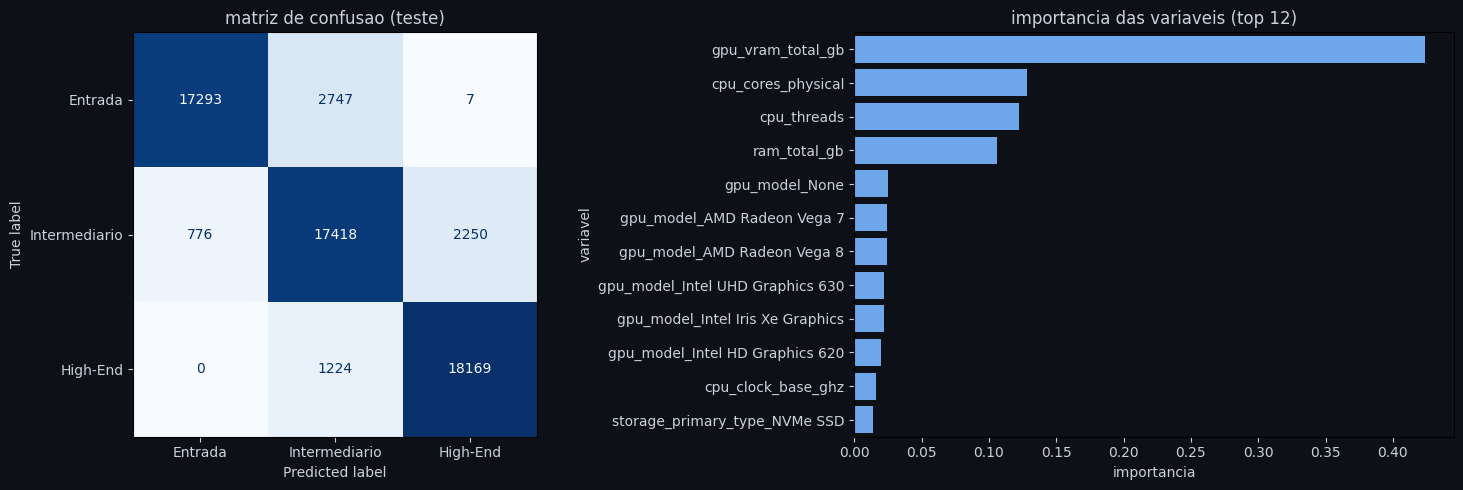

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

#alvo: tercis do score da base real (escala 0 a 10)
q33 = df_polars['system_overall_score'].quantile(0.33)
q67 = df_polars['system_overall_score'].quantile(0.67)
print(f"cortes do score: entrada <= {q33:.2f} < intermediario <= {q67:.2f} < high-end")

#somente hardware estatico (sem metricas de uso, que compoem o score)
colunas_hw = ['cpu_cores_physical', 'cpu_threads', 'cpu_clock_base_ghz', 'ram_total_gb',
              'gpu_vram_total_gb', 'storage_primary_type', 'display_resolution', 'gpu_model']

base = df_polars.select(colunas_hw + ['system_id', 'system_overall_score']).drop_nulls()
df_ml = base.sample(n=min(300_000, base.height), seed=42).to_pandas()

classes = ['Entrada', 'Intermediario', 'High-End']
df_ml['perfil'] = pd.cut(df_ml['system_overall_score'], bins=[-np.inf, q33, q67, np.inf],
                         labels=classes).astype(str)
print(df_ml['perfil'].value_counts(normalize=True).round(3))

X = pd.get_dummies(df_ml[colunas_hw], columns=['storage_primary_type', 'display_resolution', 'gpu_model'], dtype=int)
y = df_ml['perfil']

#divisao por maquina: o mesmo system_id nunca fica em treino e teste
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_tr, idx_te = next(gss.split(X, y, groups=df_ml['system_id']))
X_train, X_test, y_train, y_test = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]

#baseline: sempre a classe mais frequente
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
y_dummy = dummy.predict(X_test)

#random forest
modelo_rf = RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=20,
                                   n_jobs=-1, random_state=42).fit(X_train, y_train)
y_pred = modelo_rf.predict(X_test)

print(f"\nbaseline    -> acuracia {accuracy_score(y_test, y_dummy):.3f} | f1 macro {f1_score(y_test, y_dummy, average='macro'):.3f}")
print(f"random forest -> acuracia {accuracy_score(y_test, y_pred):.3f} | f1 macro {f1_score(y_test, y_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_pred, labels=classes))

#matriz de confusao e importancia das variaveis
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=classes, cmap='Blues',
                                        colorbar=False, ax=axes[0])
axes[0].set_title('matriz de confusao (teste)')

df_imp = (pd.DataFrame({'variavel': X.columns, 'importancia': modelo_rf.feature_importances_})
          .sort_values('importancia', ascending=False).head(12))
sns.barplot(data=df_imp, x='importancia', y='variavel', color='#58a6ff', ax=axes[1])
axes[1].set_title('importancia das variaveis (top 12)')
plt.tight_layout()
plt.show()

   k      inercia  silhouette
0  2  220916.6512      0.2670
1  3  172863.6614      0.2604
2  4  139720.4240      0.2686
3  5  116060.9424      0.2781
4  6   96249.8575      0.2921


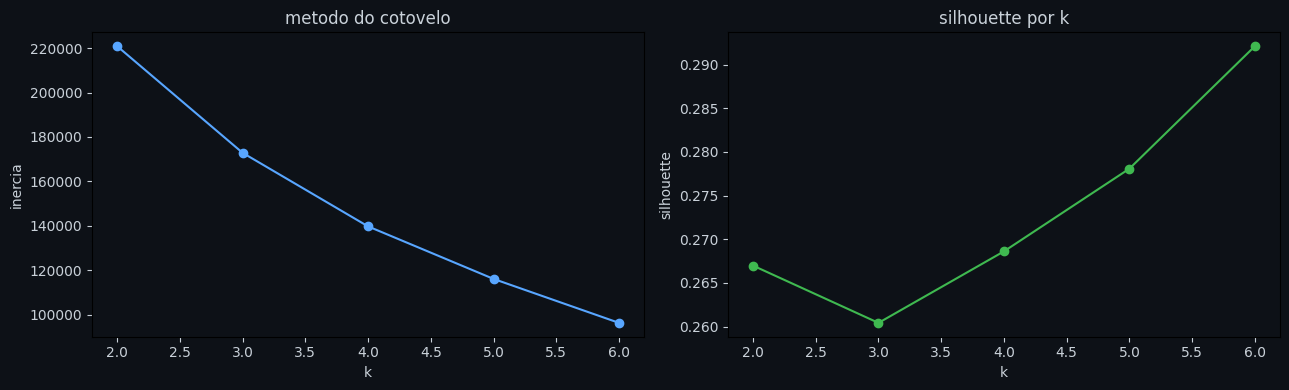


k escolhido: 6
         maquinas    cpu    ram   vram  score   pct
cluster                                            
1           16669  22.82  78.87  23.71   4.96  16.7
4           16839  29.09  32.78  10.20   4.66  16.8
2           16354  29.70  38.84  73.44   5.88  16.4
5           15875  67.94  74.01  72.68   5.68  15.9
3           17059  74.35  74.03   9.76   4.43  17.1
0           17204  79.08  29.00  32.69   5.18  17.2


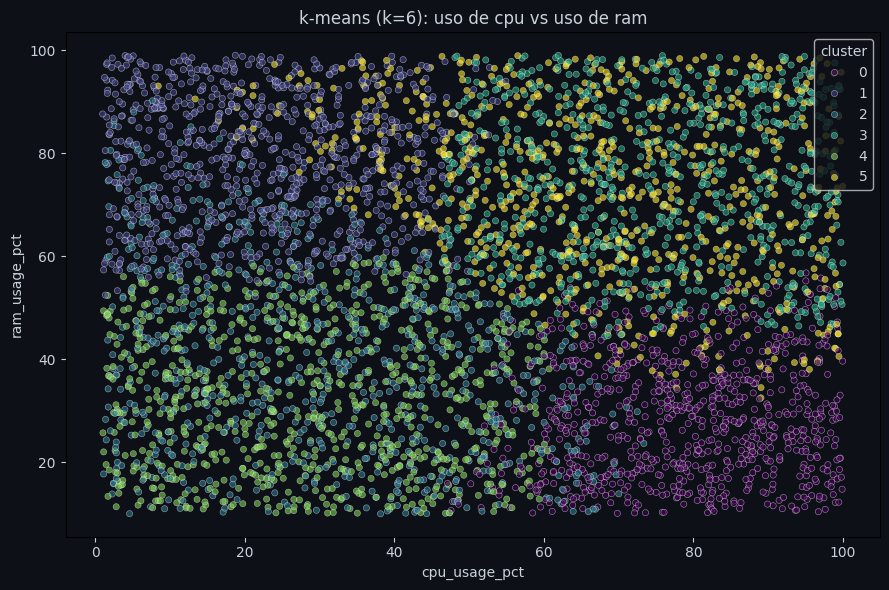

In [ ]:
from sklearn.preprocessing import StandardScaler

#perfis de uso: quais grupos de maquinas existem em termos de carga?
colunas_km = ['cpu_usage_pct', 'ram_usage_pct', 'gpu_vram_usage_pct']
base_km = df_polars.select(colunas_km + ['system_overall_score']).drop_nulls()
df_km = base_km.sample(n=min(100_000, base_km.height), seed=42).to_pandas()
X_km = StandardScaler().fit_transform(df_km[colunas_km])

#escolha de k: cotovelo (inercia) e silhouette
resultados = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_km)
    sil = silhouette_score(X_km, km.labels_, sample_size=10_000, random_state=42)
    resultados.append((k, km.inertia_, sil))
df_k = pd.DataFrame(resultados, columns=['k', 'inercia', 'silhouette'])
print(df_k.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(df_k['k'], df_k['inercia'], marker='o', color='#58a6ff')
axes[0].set_title('metodo do cotovelo'); axes[0].set_xlabel('k'); axes[0].set_ylabel('inercia')
axes[1].plot(df_k['k'], df_k['silhouette'], marker='o', color='#3fb950')
axes[1].set_title('silhouette por k'); axes[1].set_xlabel('k'); axes[1].set_ylabel('silhouette')
plt.tight_layout(); plt.show()

#modelo final com o k de maior silhouette
k_final = int(df_k.loc[df_k['silhouette'].idxmax(), 'k'])
kmeans = KMeans(n_clusters=k_final, random_state=42, n_init=10).fit(X_km)
df_km['cluster'] = kmeans.labels_
print(f"\nk escolhido: {k_final}")

#perfil de cada cluster (o score nao entrou no agrupamento: serve de validacao externa)
perfil = (df_km.groupby('cluster')
          .agg(maquinas=('cluster', 'size'),
               cpu=('cpu_usage_pct', 'mean'), ram=('ram_usage_pct', 'mean'),
               vram=('gpu_vram_usage_pct', 'mean'), score=('system_overall_score', 'mean'))
          .round(2))
perfil['pct'] = (100 * perfil['maquinas'] / perfil['maquinas'].sum()).round(1)
print(perfil.sort_values('cpu'))

amostra = df_km.sample(min(5000, len(df_km)), random_state=42)
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=amostra, x='cpu_usage_pct', y='ram_usage_pct', hue='cluster',
                palette='viridis', alpha=0.6, s=20, ax=ax)
ax.set_title(f'k-means (k={k_final}): uso de cpu vs uso de ram')
plt.tight_layout(); plt.show()

# **Processamento Distribuído (PySpark)**

## **Justificativa: uso de PySpark e não utilização de Hadoop**

**Decisão.** O pipeline principal (limpeza, Data Warehouse, OLAP e ML) roda com Polars, SQLite e scikit-learn em uma única máquina. O PySpark entra como etapa complementar: ele lê a mesma base real e reproduz uma agregação do OLAP, para mostrar que a solução migra para processamento distribuído. O Hadoop (HDFS, YARN e MapReduce) **não foi utilizado**.

| Ferramenta | Usada? | Papel / justificativa |
| :--- | :--- | :--- |
| Polars | Sim | Leitura e transformação da base completa (~5 milhões de linhas) em memória, com bom desempenho em uma máquina |
| SQLite | Sim | Data Warehouse em esquema estrela, consultas OLAP em SQL, sem servidor para administrar |
| PySpark | Sim, em escala reduzida | Valida o código distribuído (DataFrame API e Spark SQL) sobre a base real e confere os resultados com o OLAP |
| Hadoop (HDFS/YARN) | Não | Sem cluster e sem necessidade: a base cabe em uma máquina e o custo operacional não se justifica |

**Por que não Hadoop.** Hoje o armazenamento distribuído é feito, em geral, com Parquet em armazenamento de objetos, e o MapReduce foi substituído pelo Spark. Manter um cluster Hadoop (NameNode, YARN, DataNodes) para 245 MB teria custo de administração sem benefício, e não há requisito de tolerância a falhas entre nós.

**Limitação.** O Spark foi executado em modo local, sem cluster. Ele valida o código e os resultados, mas **não mede ganho de desempenho distribuído**.


In [ ]:
!pip install -q pyspark

import time, os
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

#sessao local do spark (sem cluster)
spark = (SparkSession.builder.master("local[*]")
         .appName("hardware_telemetry").config("spark.driver.memory", "4g").getOrCreate())

#le a mesma base real usada no restante do notebook
if os.path.exists(caminho_arquivo) and os.path.getsize(caminho_arquivo) > 100_000_000:
    caminho_spark = caminho_arquivo
else:
    caminho_spark = f"{PASTA}/amostra.parquet"
    df_polars.write_parquet(caminho_spark)

df_spark = spark.read.parquet(caminho_spark)
print("registros no spark:", df_spark.count())

#1) mesma agregacao em polars e em spark, com tempo
t0 = time.perf_counter()
res_polars = (df_polars.group_by('os_name')
              .agg(pl.len().alias('total'), pl.col('system_overall_score').mean().round(2).alias('media_score'))
              .sort('os_name').to_pandas())
t_polars = time.perf_counter() - t0

t0 = time.perf_counter()
res_spark = (df_spark.groupBy('os_name')
             .agg(F.count('*').alias('total'), F.round(F.avg('system_overall_score'), 2).alias('media_score'))
             .orderBy('os_name').toPandas())
t_spark = time.perf_counter() - t0

print(f"\npolars: {t_polars:.2f}s | spark (local): {t_spark:.2f}s")

# Ajuste da comparacao: convertemos apenas as colunas numericas para float ao comparar
num_cols = ['total', 'media_score']
res_polars_num = res_polars[num_cols].astype(float).round(2)
res_spark_num = res_spark[num_cols].astype(float).round(2)

print("resultados identicos:", res_polars_num.equals(res_spark_num))
print(res_spark)

#2) spark sql: mesma consulta de gargalo de RAM do olap (deve bater com o resultado do sqlite)
df_spark.createOrReplaceTempView("telemetria")
df_sql = spark.sql("""
    SELECT ram_total_gb,
           COUNT(*) AS total,
           ROUND(100.0 * SUM(CASE WHEN ram_usage_pct > 85 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_ram_critica
    FROM telemetria
    GROUP BY ram_total_gb
    ORDER BY ram_total_gb
""")
print("\nspark sql: eventos com RAM critica (>85%) por capacidade de RAM")
df_sql.show()

registros no spark: 4975224

polars: 0.92s | spark (local): 1.94s
resultados identicos: True
        os_name    total  media_score
0  Debian Linux   158058         5.05
1        Fedora    97733         5.09
2  Ubuntu Linux   412292         5.15
3    Windows 10  2751311         5.13
4    Windows 11  1460713         5.12
5         macOS    95117         5.03

spark sql: eventos com RAM critica (>85%) por capacidade de RAM
+------------+-------+---------------+
|ram_total_gb|  total|pct_ram_critica|
+------------+-------+---------------+
|           4| 394795|          15.76|
|           8|2234470|          15.71|
|          12| 347340|          15.70|
|          16|1594766|          15.75|
|          24| 147238|          15.72|
|          32| 207133|          15.71|
|          64|  49482|          15.49|
+------------+-------+---------------+



# **Insights Finais e Conclusões**

## **Resultados**

Pipeline completo sobre **4.975.224 registros e 19 variáveis** (sintéticos, cerca de 30 dias de telemetria): EDA, Data Warehouse em esquema estrela, OLAP, Machine Learning e PySpark.

| Indicador | Média | Desvio padrão |
| :--- | :--- | :--- |
| Uso de CPU (%) | 50,51 | 28,58 |
| Uso de RAM (%) | 54,50 | 25,69 |
| Uso de VRAM (%) | 36,37 | 32,55 |
| Score geral (0–10) | 5,12 | 1,49 |

- **Parque heterogêneo:** os desvios padrão altos mostram que a média esconde máquinas ociosas e no limite. CPU e RAM são os recursos mais carregados. A média de VRAM é menor porque cerca de 29% dos eventos vêm de máquinas sem GPU dedicada, com uso zero.
- **Hardware e score:** a VRAM total é o fator de maior peso (correlação de 0,82 com o score), seguida por threads (0,59), núcleos (0,53) e RAM (0,31). Com RAM > 50%, o score vai de 3,15 (HDD, 4 núcleos) a 6,82 (NVMe, 16 núcleos), e núcleos pesam mais que o tipo de disco. O score sobe também com a RAM (4,53 em 4 GB; 6,68 em 32 GB) e com a VRAM (3,55 sem GPU; 6,98 com 12 GB). Essas relações vêm das regras do score sintético.
- **Tempo e SO:** o uso é estável por dia (CPU ≈ 50,5%, ~166 mil eventos/dia) e igual entre sistemas operacionais. Não há tendência nem diferença relevante.
- **Gargalos independem da capacidade:** ~15,7% dos eventos têm RAM > 85% em qualquer tamanho de RAM (4 a 64 GB), e ~8,6% têm VRAM > 90% em qualquer GPU. Mais memória não reduziu a pressão nos dados, pois o simulador sorteia o uso de forma independente do hardware.
- **Classificação (Random Forest):** com só hardware estático, acurácia de 88,3% e F1 macro de 0,884, contra 0,341 e 0,170 do baseline. Os erros ocorrem entre classes vizinhas, e Intermediário é a mais difícil (recall 0,85). As variáveis mais importantes são VRAM, núcleos, threads e RAM, as mesmas das regras do score.
- **K-Means:** k = 6 (silhouette 0,29, o maior do intervalo 2–6). Os clusters têm tamanhos parecidos, sem grupos naturais, mas servem como perfis: sobrecarregadas (CPU 68%, RAM 74%, VRAM 73%; 15,9%) e com folga (CPU 29%, RAM 33%, VRAM 10%; 16,8%).
- **PySpark:** reproduziu a agregação do Polars (resultados idênticos) e os percentuais de RAM crítica do OLAP. Em modo local levou 1,45 s contra 0,54 s do Polars, sem ganho nesta escala.

## **Contribuição para a situação-problema**

- **Jogos:** a distribuição de núcleos, RAM, VRAM e SO apoia requisitos mínimos e recomendados. A presença e o tamanho da VRAM são o fator que mais separa as máquinas de entrada das de alto desempenho.
- **TI:** o K-Means separa máquinas sobrecarregadas das com folga, apoiando renovação e realocação. Segundo as regras do score, a VRAM é o fator de maior peso, seguida por threads e núcleos, e o tipo de disco pesa menos.
- **Plataforma:** o pipeline mostra que a coleta e a análise padronizadas são viáveis.

## **Limitações**

- **Dados sintéticos:** o uso é independente do hardware e quase uniforme, então não há grupos naturais nem relação entre capacidade e pressão. As conclusões refletem o simulador e precisam de validação com dados reais.
- **Score definido pela equipe:** o classificador mostra que o hardware explica o score, e não prevê desempenho real.
- **Período de cerca de 30 dias:** não permite avaliar sazonalidade.
- **Spark em modo local** e gráficos com amostras por limite de memória.

## **Conclusão**

O projeto entrega uma arquitetura funcional do dado bruto ao insight. Nos dados simulados, VRAM, threads, núcleos e RAM explicam o score, e CPU e RAM são os recursos mais pressionados, sem relação com a capacidade instalada. Os resultados devem ser confirmados com dados reais antes de embasar decisões financeiras.